# Brecha digital y no uso de internet: ENAHO + ESCALE 2025

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from scientific_audit import evaluate, sha
pd.set_option('display.precision',9)
def audit(phase):
    with threadpool_limits(limits=4): record=evaluate(phase)
    display(pd.DataFrame(record['checks']))
    print('Controles ejecutados:',len(record['checks']),'| Estado:',record['status'])
    print(record['evaluation_note'])
    return record['detail']
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name))
def figure(name):
    path=ROOT/'reports/figures'/name
    print('Figura:',name,'| SHA-256:',sha(path))
    display(Image(filename=str(path)))
print('Evaluación de modelos y controles de integridad científica')


Evaluación de modelos y controles de integridad científica


**Inteligencia Artificial · Universidad Peruana Unión**

Estudio del no uso de internet en estudiantes de 6 a 17 años mediante integración de datos, segmentación, clasificación y explicabilidad. La evaluación utiliza modelos ajustados con validación agrupada por conglomerado. El carácter retrospectivo de la evaluación requiere validación externa independiente.

## Integración de datos y análisis exploratorio

La unidad de análisis es la persona residente habitual de 6 a 17 años. Se verifican llaves, variables, transformaciones, población, pesos y particiones del dataset anual de 2025. La secuencia de filas se especifica mediante SHA-256. La procedencia y el procedimiento de integración se describen en docs/SOURCE_RECONCILIATION.md.

${PROJECT_ROOT}/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,name,passed
0,frozen_models/best_model.joblib,True
1,frozen_models/all_models.joblib,True
2,frozen_models/clustering.joblib,True
3,frozen_data/processed/dataset_enaho_escale_202...,True
4,frozen_data/processed/dataset_modelado_interne...,True
5,dataset_sha256,True
6,implementation_sha256,True
7,unique_person_keys,True
8,unique_partition_indices,True
9,group_labels_aligned,True


Controles ejecutados: 41 | Estado: passed
Evaluación retrospectiva sobre una partición de prueba previamente examinada; los resultados requieren validación externa independiente.


,n_integrated,n_model,n_train,n_test,group_overlap,dataset_sha256
0,23345,16544,13105,3439,0,e46ff2b57a84c34319b94609460a7d7a0972be087a93cb...


,objetivo,n_validos,n_positivos,n_negativos,prevalencia_muestral,prevalencia_ponderada,conglomerados
0,target_rezago,16544,6707,9837,0.405403772,0.403578149,4040
1,target_rezago_2,16544,679,15865,0.041042070,0.038354976,4040
2,target_internet,16544,4294,12250,0.259550290,0.226710658,4040


,etapa,n,excluidos_en_etapa
0,Base integrada residentes6-17,23345,0
1,Edad6-17,23345,0
2,Matriculados P306=1,20058,3287
3,Asistentes P307=1,17807,2251
4,Primaria/secundaria P308A2/3,17080,727
5,Sin CEBA declarado,16544,536
6,Respuesta válida P314A1/2,16544,0
7,Peso individual positivo,16544,0


Figura: raw_eda.png | SHA-256: 410751831470d80bfa7946de218bc4c7ad92965ed3c82dca1fb42179ad3f7910


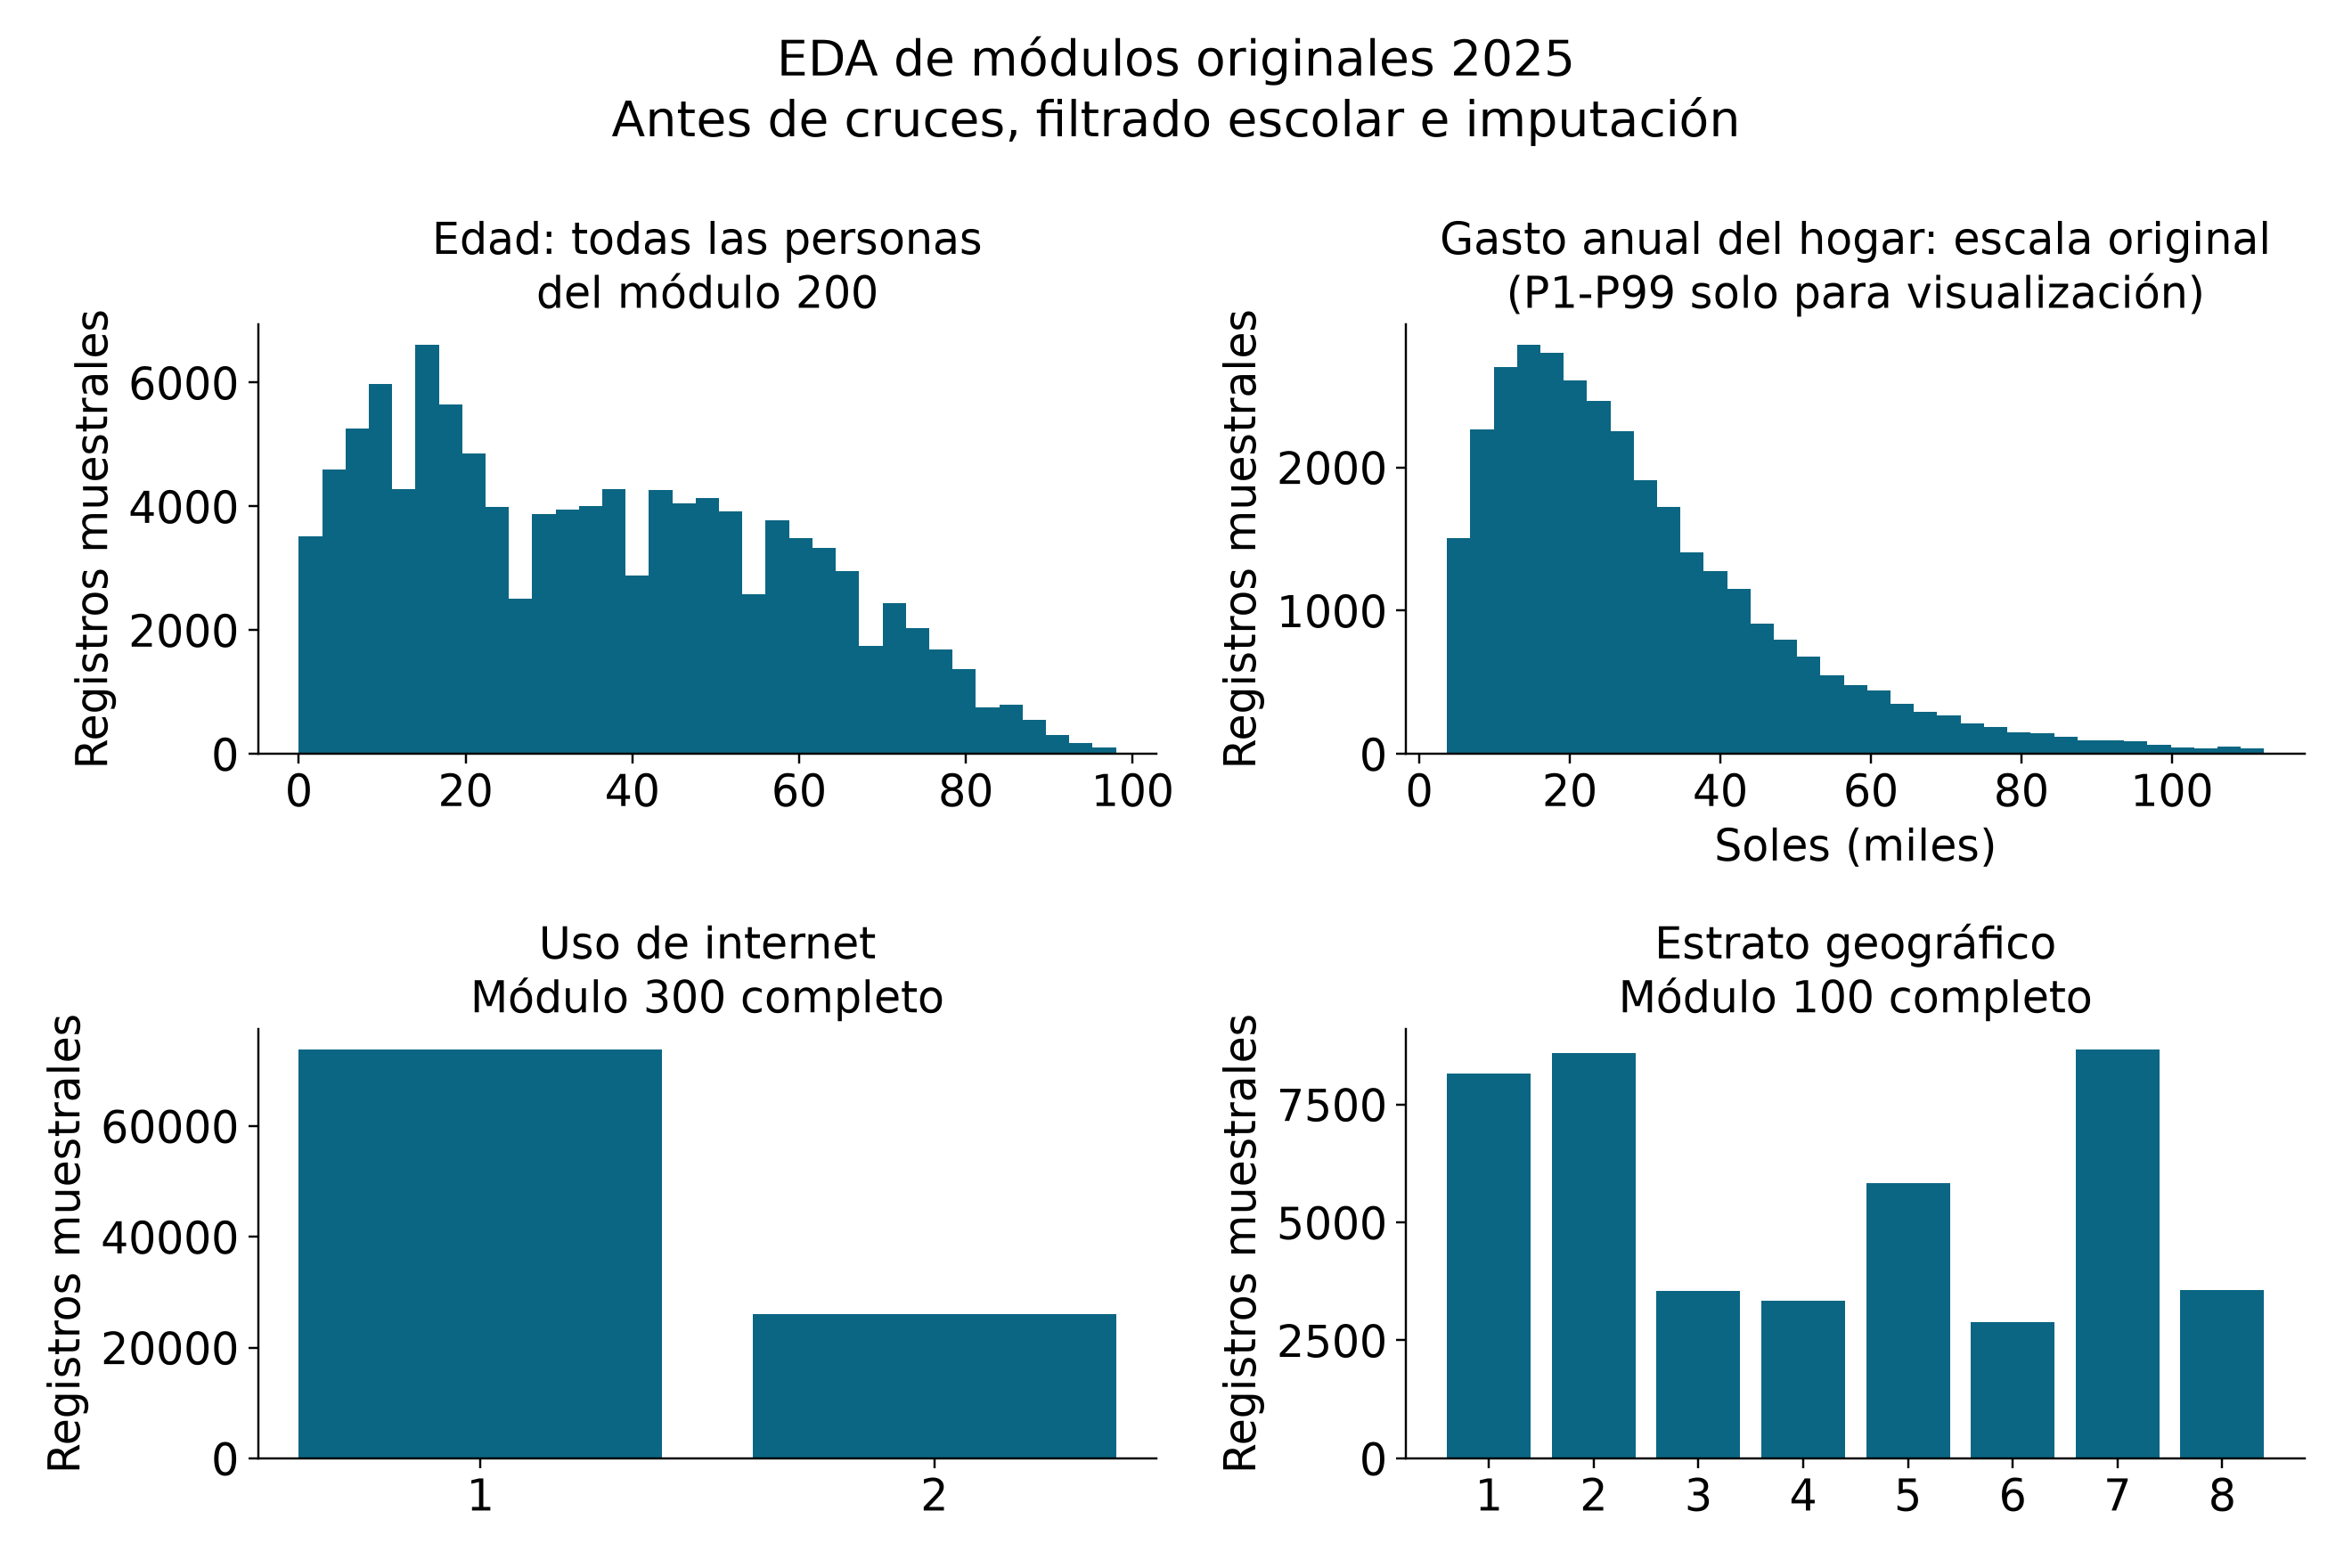

Figura: eda.png | SHA-256: da8ffac9b7074b35d04f539319443586d5b19213b4981e7507f201de728a295e


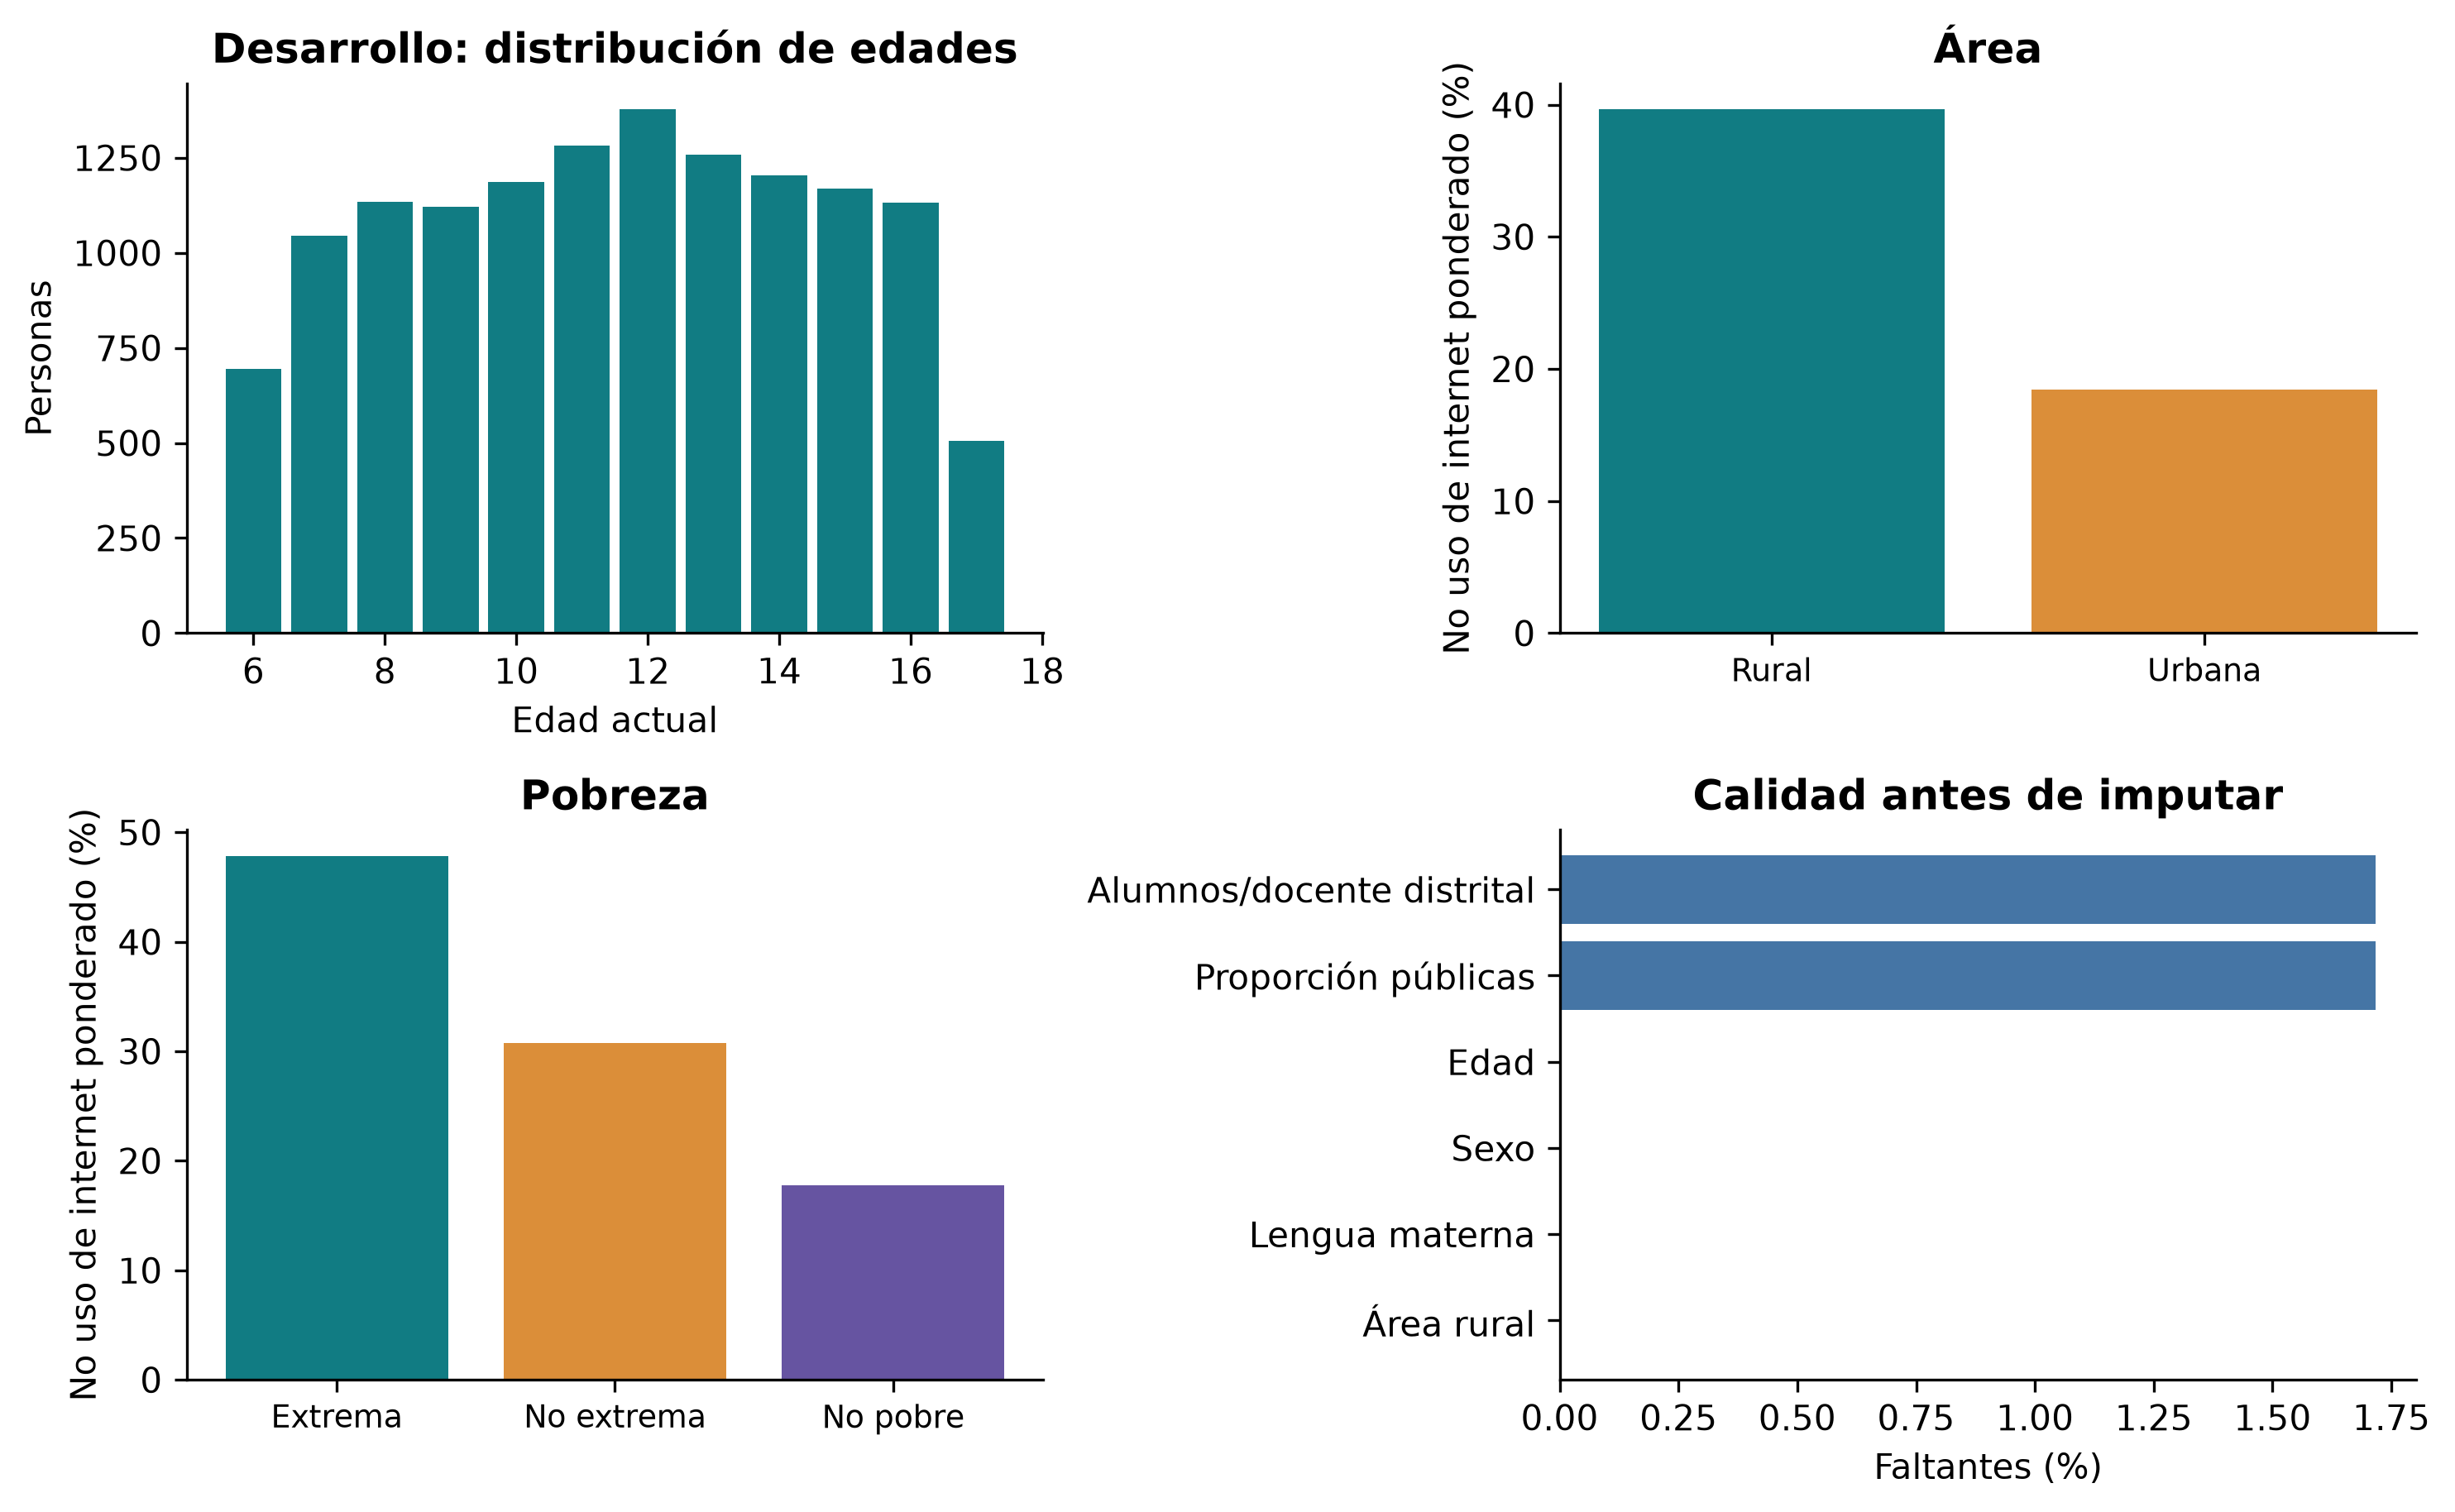

In [2]:
detail=audit('dataset')
display(pd.DataFrame([detail]))
table('target_comparison.csv')
table('population_flow_model.csv')
figure('raw_eda.png')
figure('eda.png')

## Segmentación y perfiles socioeducativos

Se evalúa el GMM guardado de dos componentes. Se recalculan asignaciones, silueta en 2 500 casos con semilla 42, Davies–Bouldin y Calinski–Harabasz en desarrollo; se contrastan tamaños y tasas ponderadas. La etiqueta no interviene en el ajuste ni la selección. La comparación completa y la ablación se contrastan también mediante entrenamiento aislado.

,name,passed
0,saved_gmm_k2,True
1,train_assignments,True
2,test_assignments,True
3,geometry_silueta,True
4,geometry_davies_bouldin,True
5,geometry_calinski_harabasz,True
6,imputer_development_only,True
7,profile_size_0,True
8,profile_nonuse_0,True
9,profile_size_1,True


Controles ejecutados: 11 | Estado: passed
Evaluación retrospectiva sobre una partición de prueba previamente examinada; los resultados requieren validación externa independiente.


,metodo,k,silueta,davies_bouldin,calinski_harabasz
0,GMM,2,0.453928052,1.452377688,3037.70139701


Ablación: {'features': ['log_ingreso_pc', 'log_gasto_pc', 'altitud', 'ratio_alumnos_docente', 'prop_publicas'], 'silueta': 0.27913214200381065, 'ari_vs_completo': 0.08075259236459058, 'note': 'Mismo metodo y k sin electricidad/internet; diagnostico de dependencia de acceso, no nueva seleccion por etiqueta.'}


,metodo,k,silueta,davies_bouldin,calinski_harabasz,min_proporcion,elegible
0,KMeans,2,0.323305324,1.397657792,5337.305215201,0.379473483,True
1,KMeans,3,0.340767961,1.148999119,4925.559537406,0.040976726,False
2,KMeans,4,0.359772630,0.994546183,4980.049849711,0.040976726,False
3,KMeans,5,0.278875027,1.148662969,5110.992737901,0.040976726,False
4,KMeans,6,0.274484612,1.140055651,4964.759806459,0.040900420,False
5,GMM,2,0.453928052,1.452377688,3037.701397010,0.096985883,True
6,GMM,3,0.458154061,1.018345301,2407.406842822,0.024494468,False
7,GMM,4,0.284158605,1.168781170,3621.382092528,0.024494468,False
8,GMM,5,0.223463708,1.473965873,3725.815201730,0.040976726,False
9,GMM,6,0.228435185,1.386974606,3266.700689176,0.016482259,False


,cluster,n,proporcion,no_uso_ponderado,edad,rural,internet_hogar,electricidad,ingreso_pc_mensual,gasto_pc_mensual,altitud,ratio_alumnos_docente,prop_publicas,prop_pobreza,prop_castellano,perfil
0,0,1271,0.096985883,0.477435211,11.126418825,0.589310262,0.486262323,0.403425685,486.282471057,474.033284275,1411.204470494,13.478031220,0.773488063,0.465266448,0.815370738,Menor conectividad; rural
1,1,11834,0.903014117,0.210705478,11.545063077,0.182562994,1.000000000,1.000000000,853.471358713,704.691679573,1170.147263942,15.922128688,0.539919143,0.307014186,0.955153026,Mayor conectividad; urbano


,seed,tipo,ari_vs_seleccion
0,42,semilla,1.0
1,42,submuestra80,1.0
2,43,semilla,1.0
3,43,submuestra80,1.0
4,44,semilla,1.0
5,44,submuestra80,1.0


Figura: clustering.png | SHA-256: 81eb45326e4812a5edb94ca9fd24e017b83fef59be17ef8655b1c71887449bac


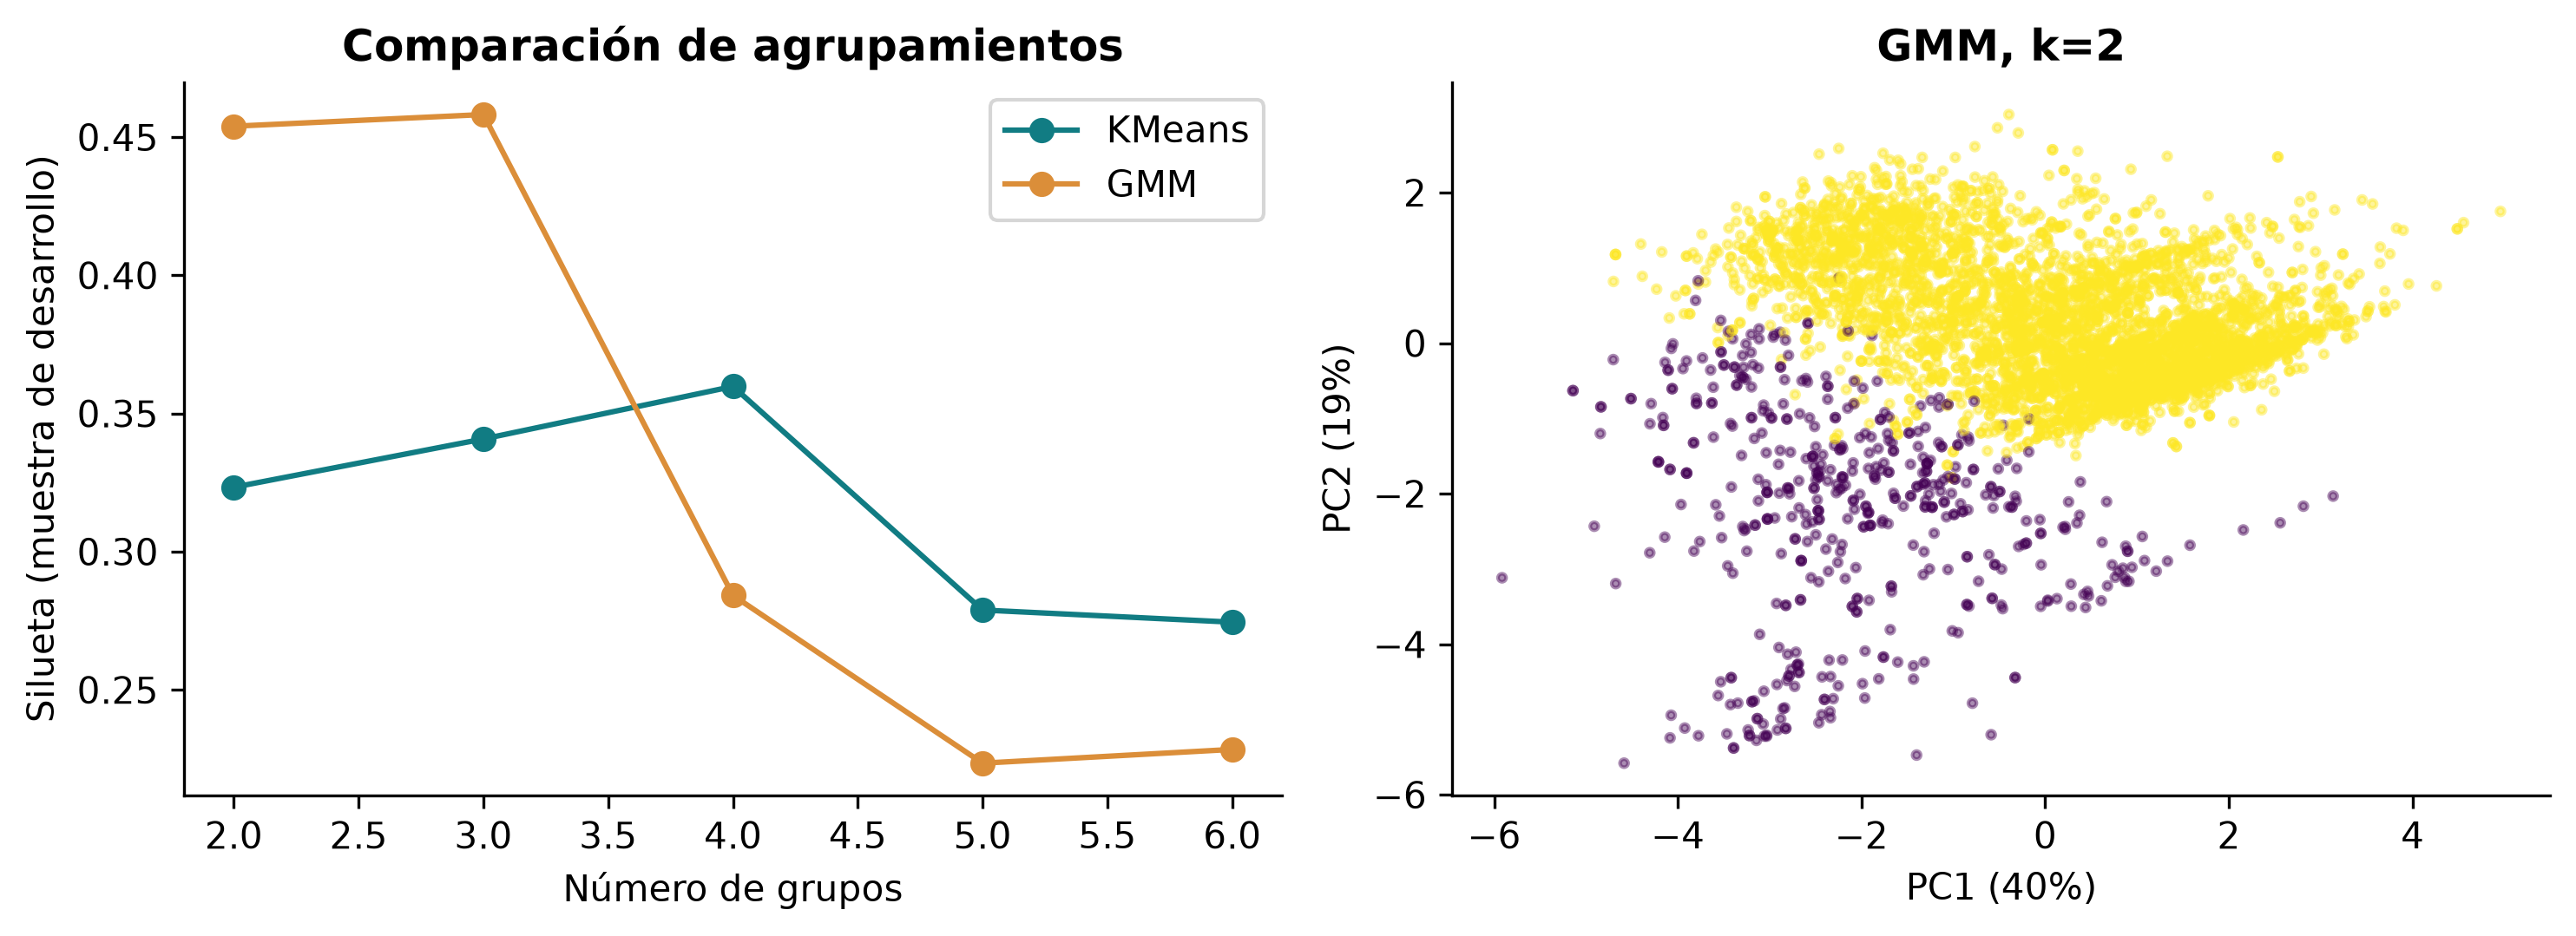

Figura: silhouette.png | SHA-256: dde5034f59f3f92b54f29dcaf734af7ad333d8273fe9040c60f44fc231bceda8


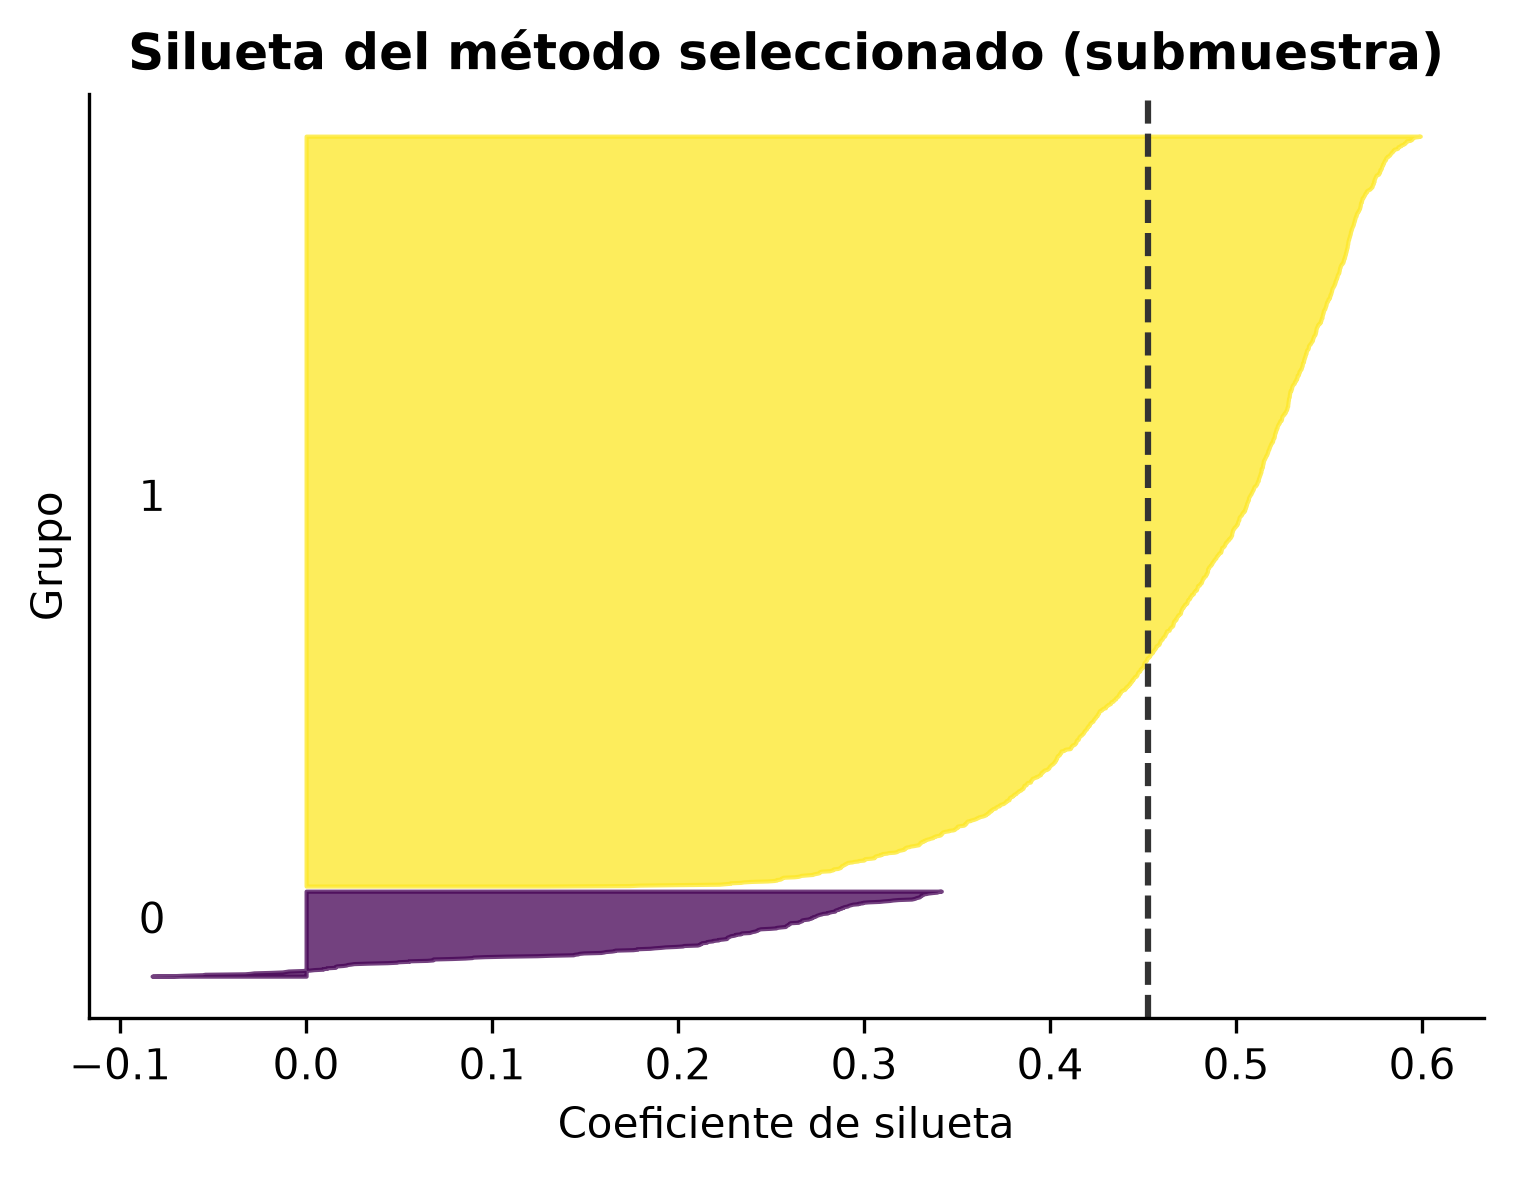

In [3]:
detail=audit('clustering')
display(pd.DataFrame([detail['selected']]))
print('Ablación:',detail['access_ablation'])
table('clustering_comparison.csv')
table('cluster_profiles.csv')
table('clustering_stability.csv')
figure('clustering.png')
figure('silhouette.png')

## Clasificación del no uso de internet

Se recalculan predicciones de los cuatro modelos guardados, alineadas por índice y orden. Se verifican columnas, preprocesamiento, pesos, calibración y métricas. La comprobación de calibración reajusta únicamente la sigmoide sobre las predicciones OOF originales de desarrollo. No utiliza prueba. Los clasificadores se mantienen congelados; el entrenamiento completo de 200 ajustes se reproduce y compara aparte. El ganador se seleccionó por AP de cinco folds GroupKFold; las transformaciones se ajustaron dentro de cada fold. Umbral fijo: 0.5. La prueba fue observada anteriormente: esta evaluación es retrospectiva, no una validación externa inédita.

,name,passed
0,test_prediction_order,True
1,oof_development_order,True
2,test_target,True
3,test_weights,True
4,oof_target,True
...,...,...
86,unweighted_CatBoost_recall,True
87,unweighted_CatBoost_brier,True
88,unweighted_CatBoost_specificity,True
89,best_bundle_predictions,True


Controles ejecutados: 91 | Estado: passed
Evaluación retrospectiva sobre una partición de prueba previamente examinada; los resultados requieren validación externa independiente.
Ganador: CatBoost | Umbral: 0.5


,modelo,roc_auc,average_precision,pr_auc_trapezoidal,f1_macro,precision,recall,brier,specificity
0,Logística,0.815614131,0.585869130,0.585244785,0.680088429,0.649656382,0.368829185,0.128950167,0.943892053
1,Random Forest,0.814107256,0.585039573,0.584410490,0.674373021,0.643271568,0.358374388,0.129366712,0.943937956
2,XGBoost,0.817426561,0.595340404,0.594755289,0.688293704,0.657350544,0.384628899,0.128227327,0.943443369
3,CatBoost,0.820356650,0.601272493,0.600665989,0.693293954,0.690898863,0.381180843,0.127282458,0.951893275


,modelo,config,parametros,ap_cv_media,ap_cv_sd,auc_cv_media,f1_cv_media,estrategia_peso,segundos
0,CatBoost,0,"{""depth"": 3, ""l2_leaf_reg"": 3}",0.593465535,0.010856842,0.818595916,0.699880584,class,2.603240167
1,XGBoost,1,"{""max_depth"": 3, ""min_child_weight"": 1, ""reg_l...",0.593073633,0.016343451,0.817087280,0.690111392,uniform,1.203861208
2,Logística,1,"{""C"": 0.03}",0.588552190,0.025634229,0.816913979,0.670693522,uniform,0.172765083
3,Random Forest,0,"{""max_depth"": 8, ""min_samples_leaf"": 10, ""max_...",0.580912634,0.024842249,0.807852073,0.631638469,uniform,1.826540916


,modelo,seleccionado_cv,roc_auc,average_precision,pr_auc_trapezoidal,f1_macro,precision,recall,brier,specificity,brier_sin_calibrar,f1_macro_no_ponderado,auc_no_ponderado,roc_auc_no_ponderado,average_precision_no_ponderado,pr_auc_trapezoidal_no_ponderado,precision_no_ponderado,recall_no_ponderado,brier_no_ponderado,specificity_no_ponderado
0,Logística,False,0.815614131,0.585869130,0.585244785,0.680088429,0.649656382,0.368829185,0.128950167,0.943892053,0.128959665,0.714428601,0.839045954,0.839045954,0.656319273,0.656044236,0.663974152,0.472957422,0.132976640,0.919066148
1,Random Forest,False,0.814107256,0.585039573,0.584410490,0.674373021,0.643271568,0.358374388,0.129366712,0.943937956,0.131097309,0.720222229,0.832680795,0.832680795,0.654111348,0.653828268,0.660990712,0.491369390,0.134128472,0.914785992
2,XGBoost,False,0.817426561,0.595340404,0.594755289,0.688293704,0.657350544,0.384628899,0.128227327,0.943443369,0.128460448,0.722367537,0.840311329,0.840311329,0.666466599,0.666216702,0.674641148,0.486766398,0.131711347,0.920622568
3,CatBoost,True,0.820356650,0.601272493,0.600665989,0.693293954,0.690898863,0.381180843,0.127282458,0.951893275,0.161579669,0.717705492,0.840619837,0.840619837,0.665313395,0.665056904,0.686440678,0.466052934,0.131657431,0.928015564


,modelo,estrategia,ap_cv_media,ap_oof_no_ponderada,brier_oof_ponderado,ap_oof_peso_educacion,segundos
0,Logística,uniform,0.587466558,0.663589685,0.133100079,0.596696880,0.161149000
1,Logística,population,0.585403241,0.656498501,0.133429551,0.594859178,0.174047750
2,Logística,class,0.587352046,0.663119546,0.162729554,0.596781837,0.179005625
3,Logística,population_class,0.584980495,0.656331206,0.176369258,0.594982848,0.182871417
4,Random Forest,uniform,0.580912634,0.658025278,0.136463378,0.590134708,1.891699791
5,Random Forest,population,0.575313480,0.655244309,0.137719039,0.585598087,1.666161542
6,Random Forest,class,0.577423111,0.656014868,0.165649149,0.587072212,1.923327041
7,Random Forest,population_class,0.572435488,0.651685977,0.177349870,0.583360221,1.723411416
8,XGBoost,uniform,0.591272889,0.669419707,0.132415941,0.601246681,0.896118208
9,XGBoost,population,0.583773051,0.660342544,0.133366402,0.594876649,0.905245541


Figura: model_curves.png | SHA-256: 484e053c4523a40a27d46661fb6e4c17f0f0e5b9bf8930e273f05f786440de6c


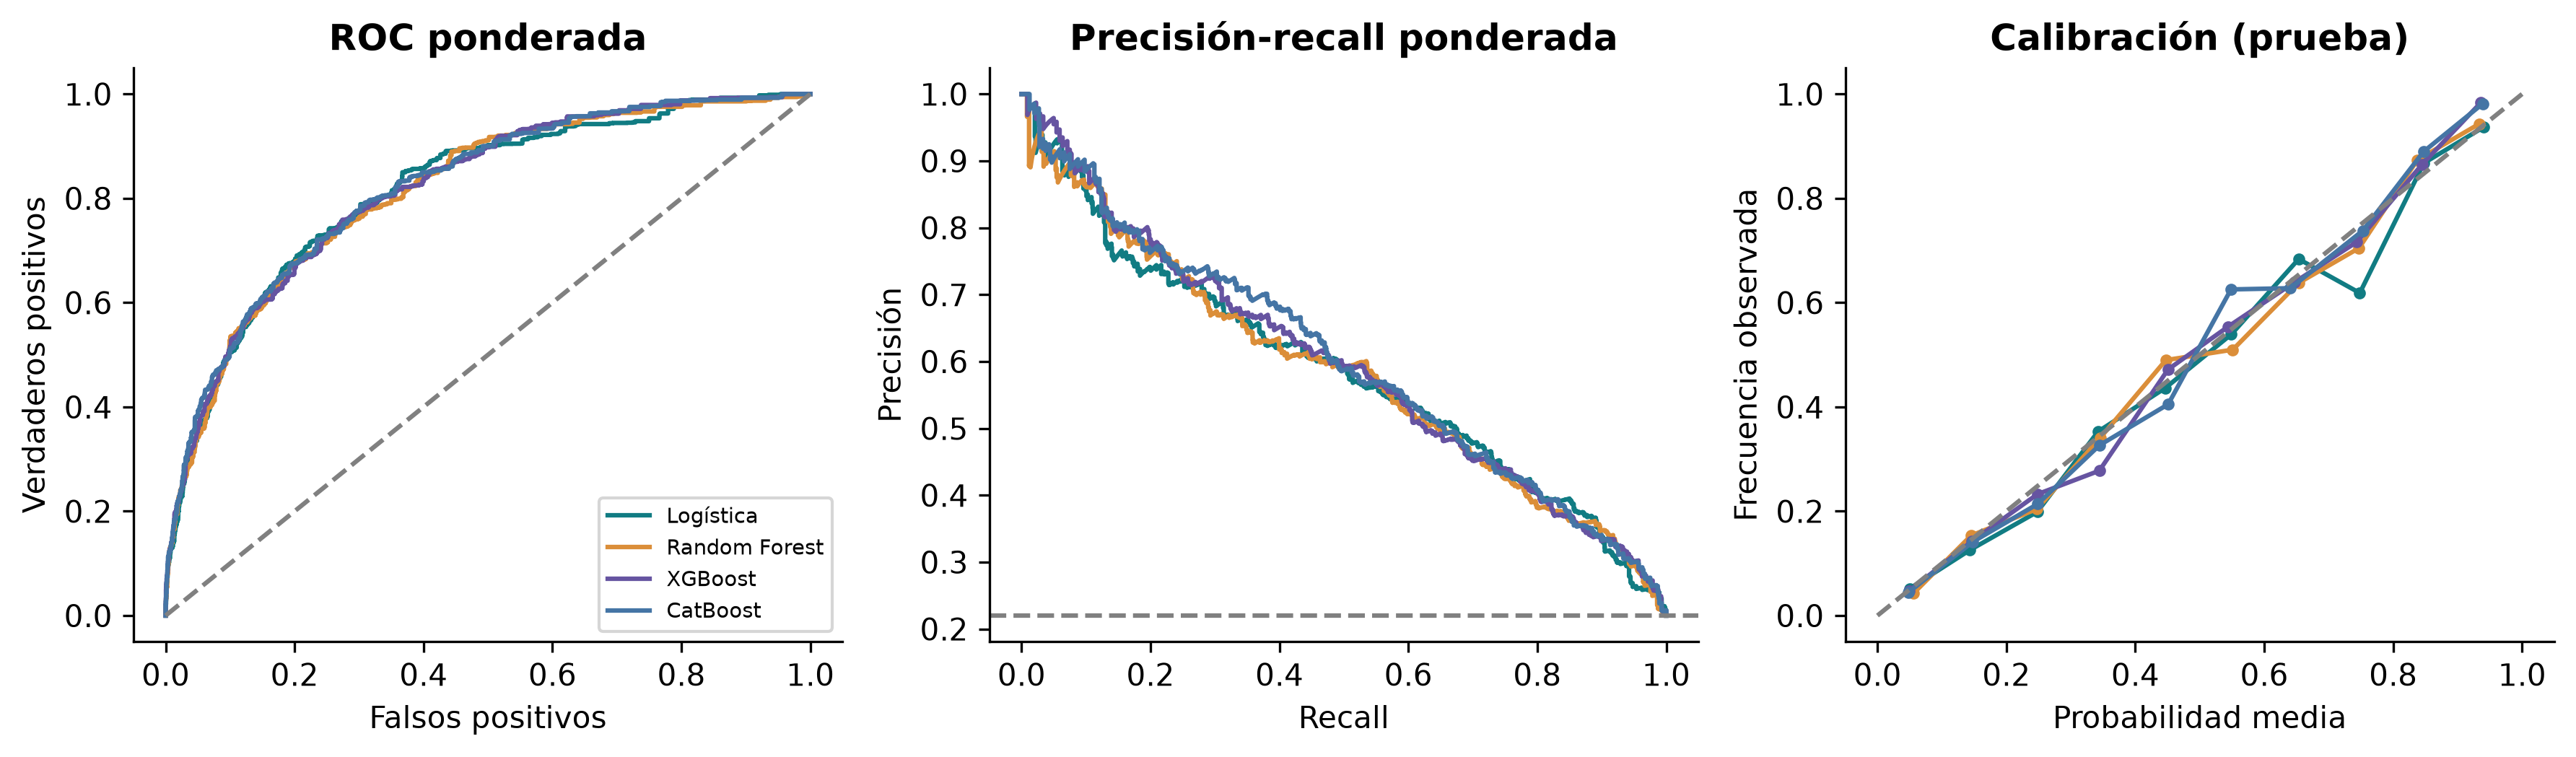

Figura: confusion_matrix.png | SHA-256: f27d7e202093be73121afd5b99f5a0e2b08ce4f88f4b763ae188ede84dd67e4d


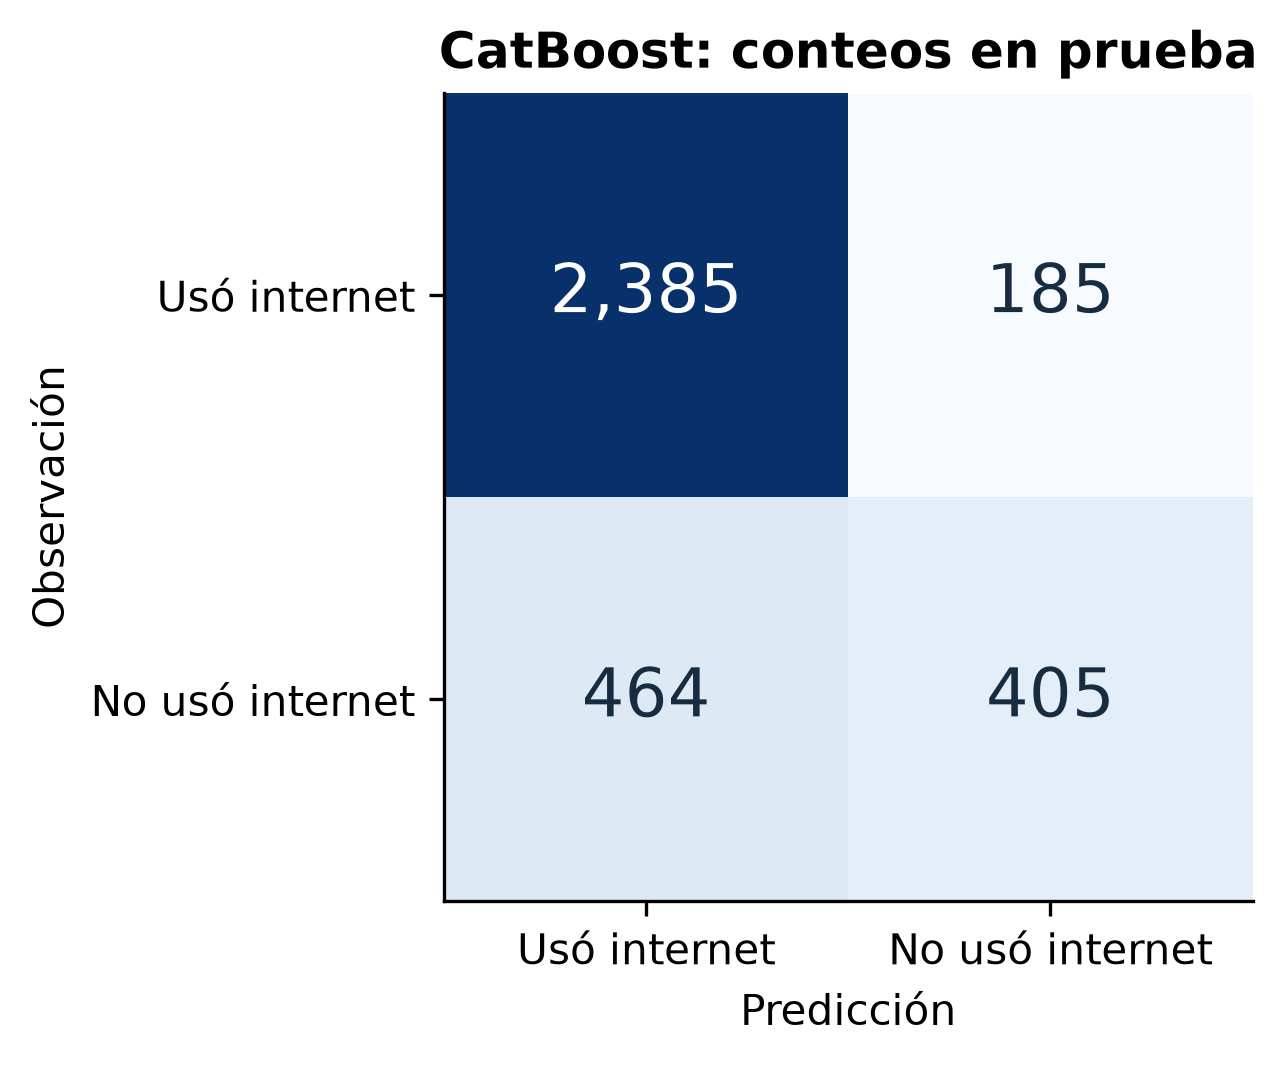

In [4]:
detail=audit('classification')
print('Ganador:',detail['winner'],'| Umbral:',detail['threshold'])
display(pd.DataFrame(detail['metrics']))
table('model_comparison_cv.csv')
table('model_comparison_test.csv')
table('weight_sensitivity.csv')
figure('model_curves.png')
figure('confusion_matrix.png')

## Explicabilidad e interacciones predictivas

Se recalculan TreeSHAP del CatBoost guardado e interacciones de XGBoost, un complemento que no sustituye al ganador. Se verifican muestra, aditividad, importancia, scores y contribuciones de casos. Las unidades son log-odds anteriores a calibrar, no puntos porcentuales de probabilidad. Las figuras son artefactos definitivos identificados por hash. SHAP describe el modelo, no demuestra causalidad ni mide competencias digitales.

,name,passed
0,catboost_shap_additivity,True
1,catboost_shap_importance,True
2,catboost_shap_sample,True
3,case_probability_alto,True
4,case_score_alto,True
5,case_alto_edad,True
6,case_alto_internet_hogar,True
7,case_alto_electricidad,True
8,case_alto_log_gasto_pc,True
9,case_alto_lengua_materna,True


Controles ejecutados: 29 | Estado: passed
Evaluación retrospectiva sobre una partición de prueba previamente examinada; los resultados requieren validación externa independiente.
Modelo: CatBoost | Casos: 601 | Residuo: 6.217248937900877e-15


,variable,mean_abs_shap
0,edad,1.057028265
9,log_gasto_pc,0.444137165
11,prop_publicas,0.223087357
2,lengua_materna,0.146127276
5,electricidad,0.136770732
3,rural,0.125099883
8,log_ingreso_pc,0.110145921
7,altitud,0.094581220
6,internet_hogar,0.080215001
10,ratio_alumnos_docente,0.054355979


Complemento: XGBoost | Residuo: 2.384185791015625e-06


,variable,mean_abs_shap
0,edad,1.057028265
1,log_gasto_pc,0.444137165
2,prop_publicas,0.223087357
3,lengua_materna,0.146127276
4,electricidad,0.136770732
5,rural,0.125099883
6,log_ingreso_pc,0.110145921
7,altitud,0.094581220
8,internet_hogar,0.080215001
9,ratio_alumnos_docente,0.054355979


,variable_1,variable_2,mean_abs_pair_contribution
0,altitud,prop_publicas,0.038718475
1,altitud,ratio_alumnos_docente,0.028174848
2,internet_hogar,log_gasto_pc,0.025224551
3,log_ingreso_pc,log_gasto_pc,0.022771416
4,log_gasto_pc,prop_publicas,0.020289938
5,altitud,log_gasto_pc,0.018519097
6,log_ingreso_pc,prop_publicas,0.014942284
7,log_gasto_pc,ratio_alumnos_docente,0.014395046
8,lengua_materna,altitud,0.013842541
9,rural,log_gasto_pc,0.012626567


Figura: shap_beeswarm.png | SHA-256: c197c5179e98708b7785dad5bea89ac067b2c6c6dae30aabee4a57c9cca3ebe5


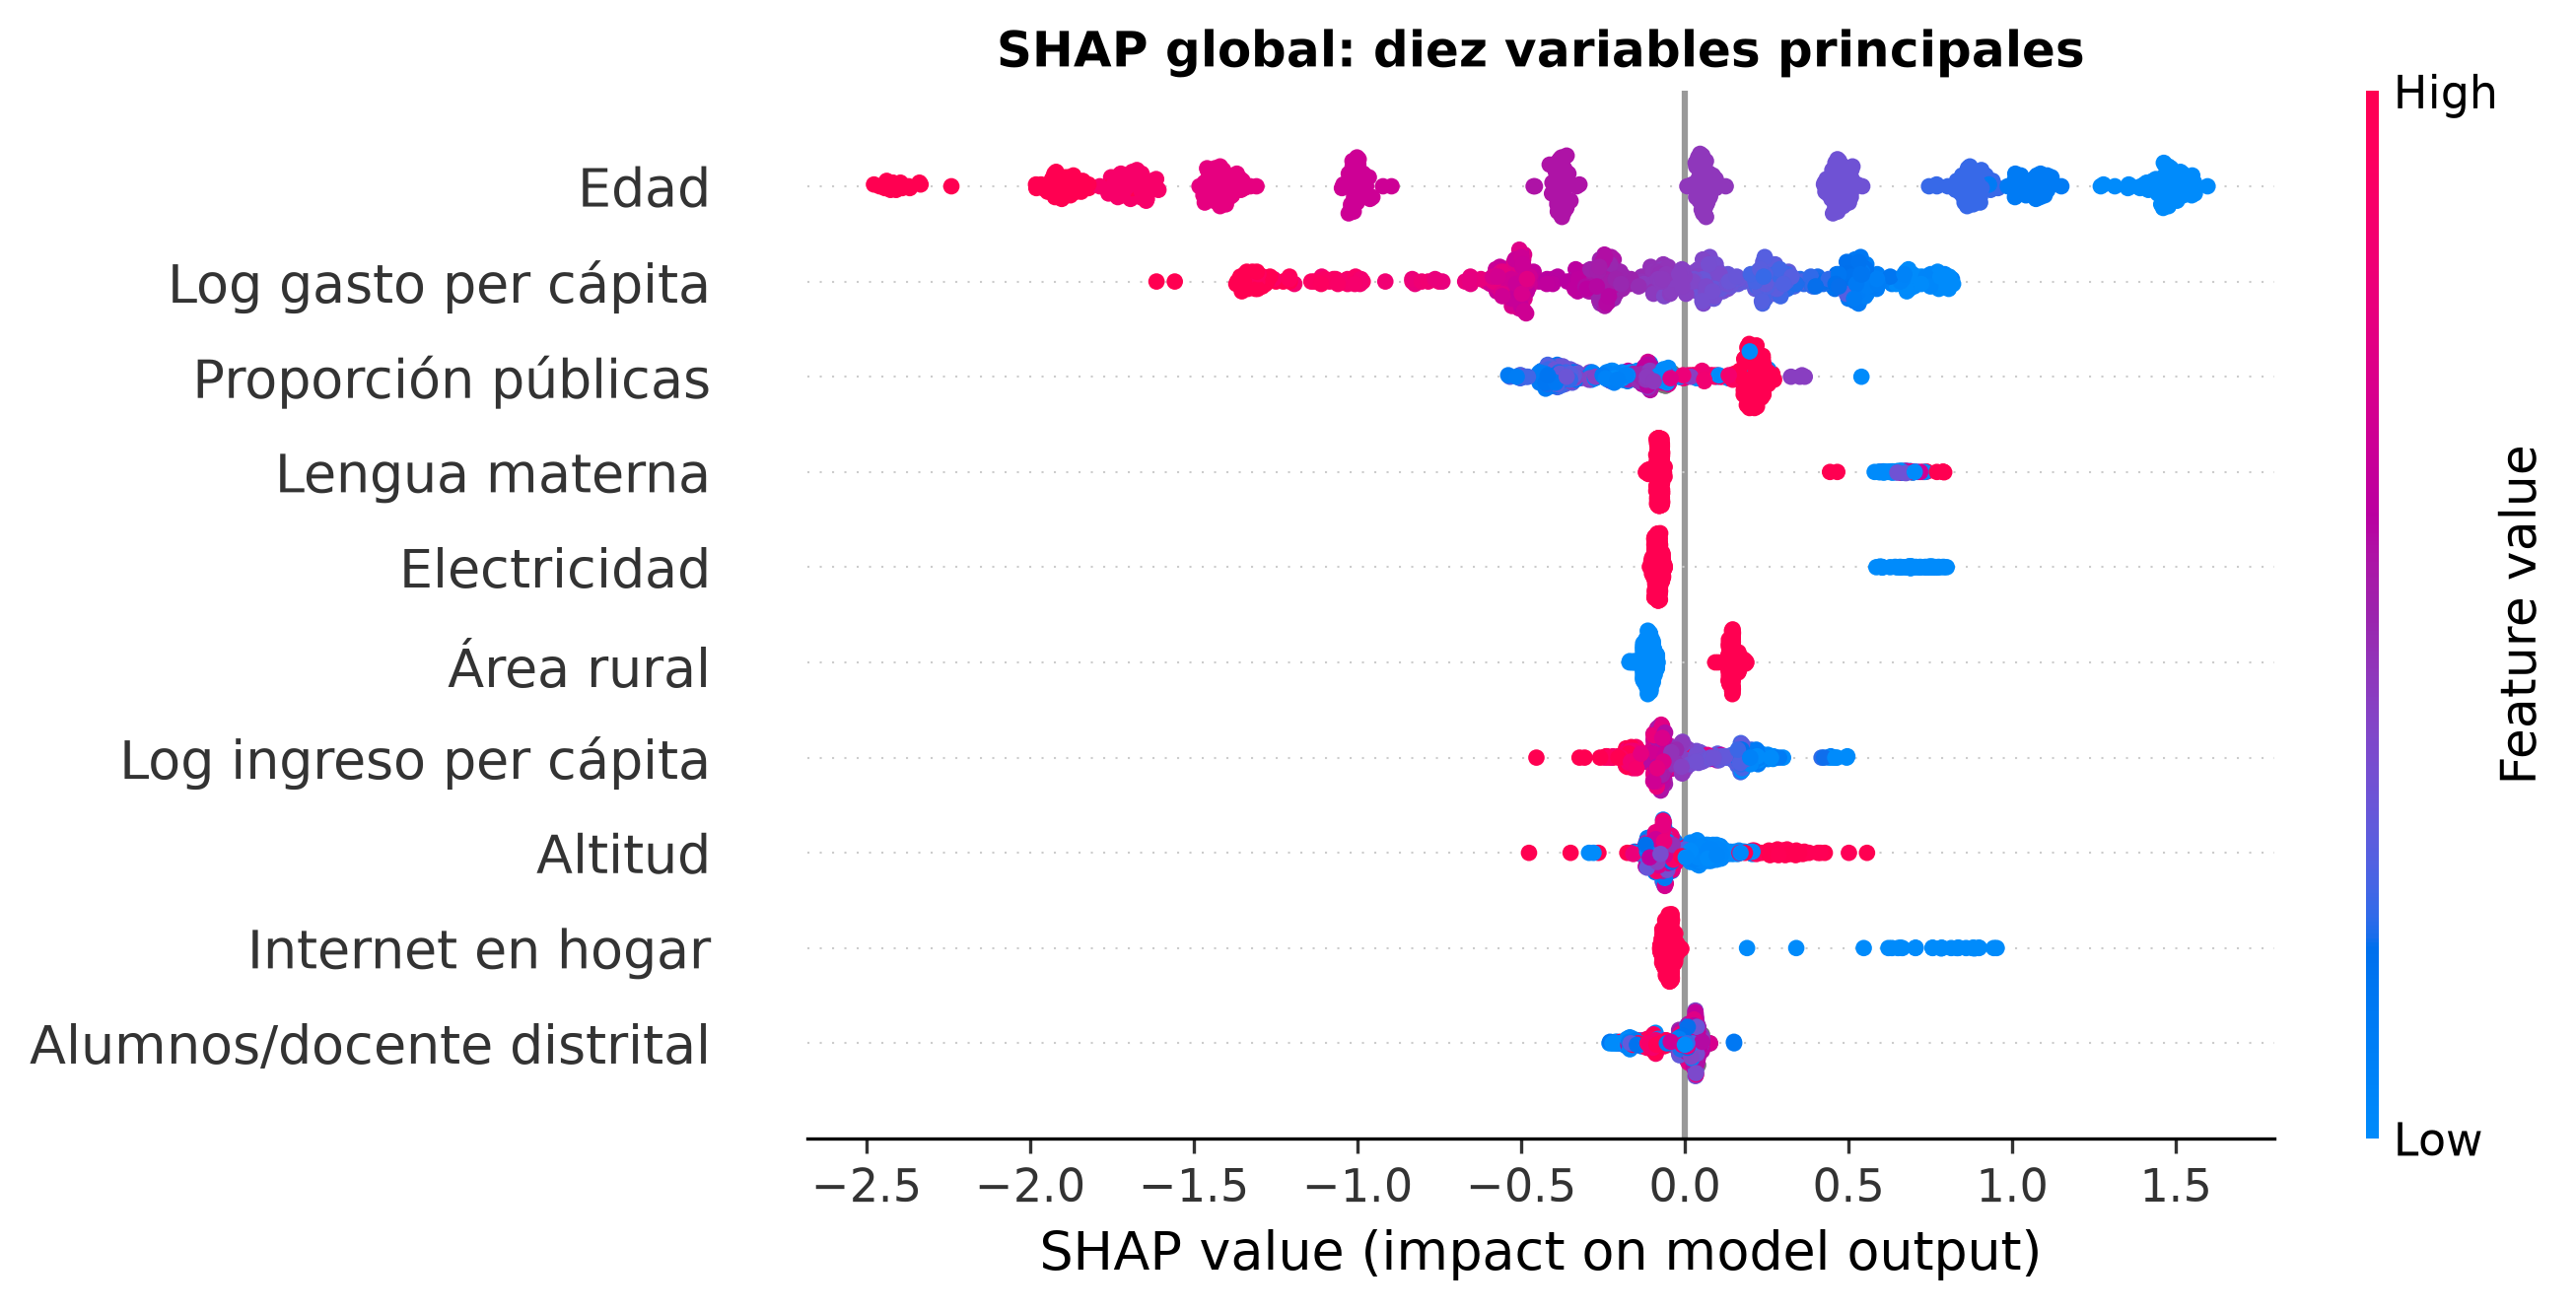

Figura: shap_dependence_1.png | SHA-256: 0f1271e9e2b4e9da7a59aa263cbb3bf6ad480bad9b0d805541e07ed0278e4068


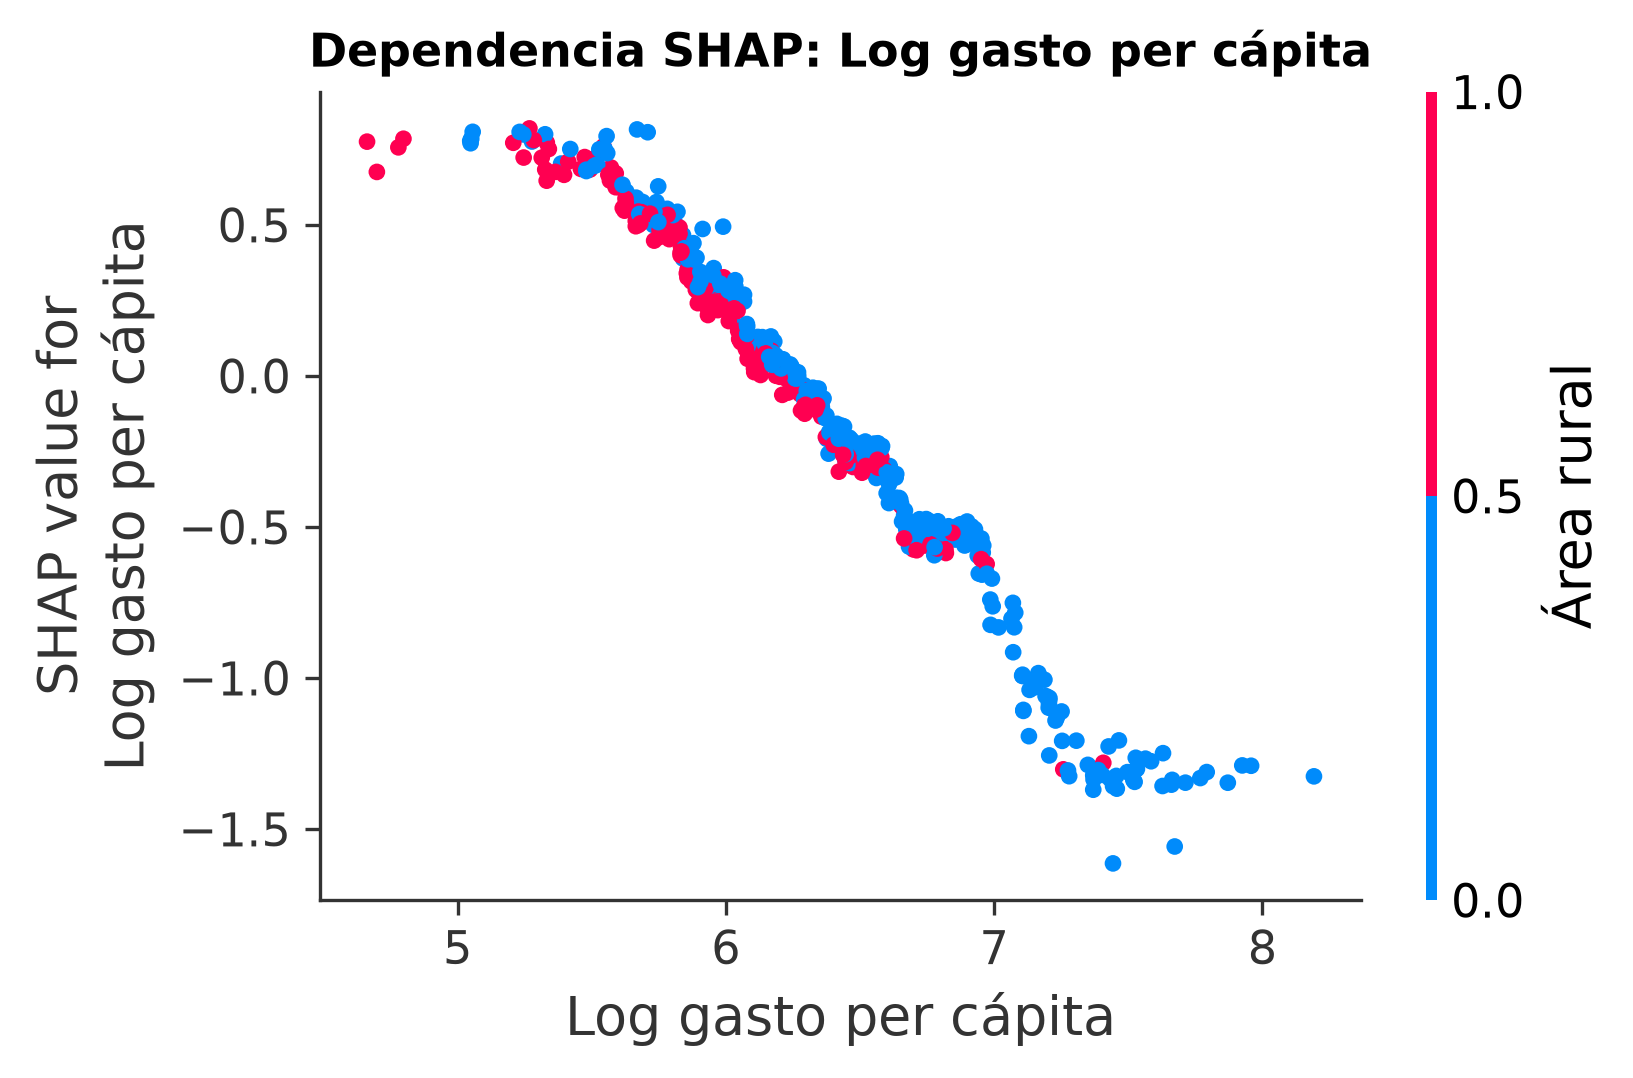

Figura: shap_dependence_2.png | SHA-256: 27a9afc65d4d8908e91c746fca69f39f2d6aa0bc5122242a286624194234550a


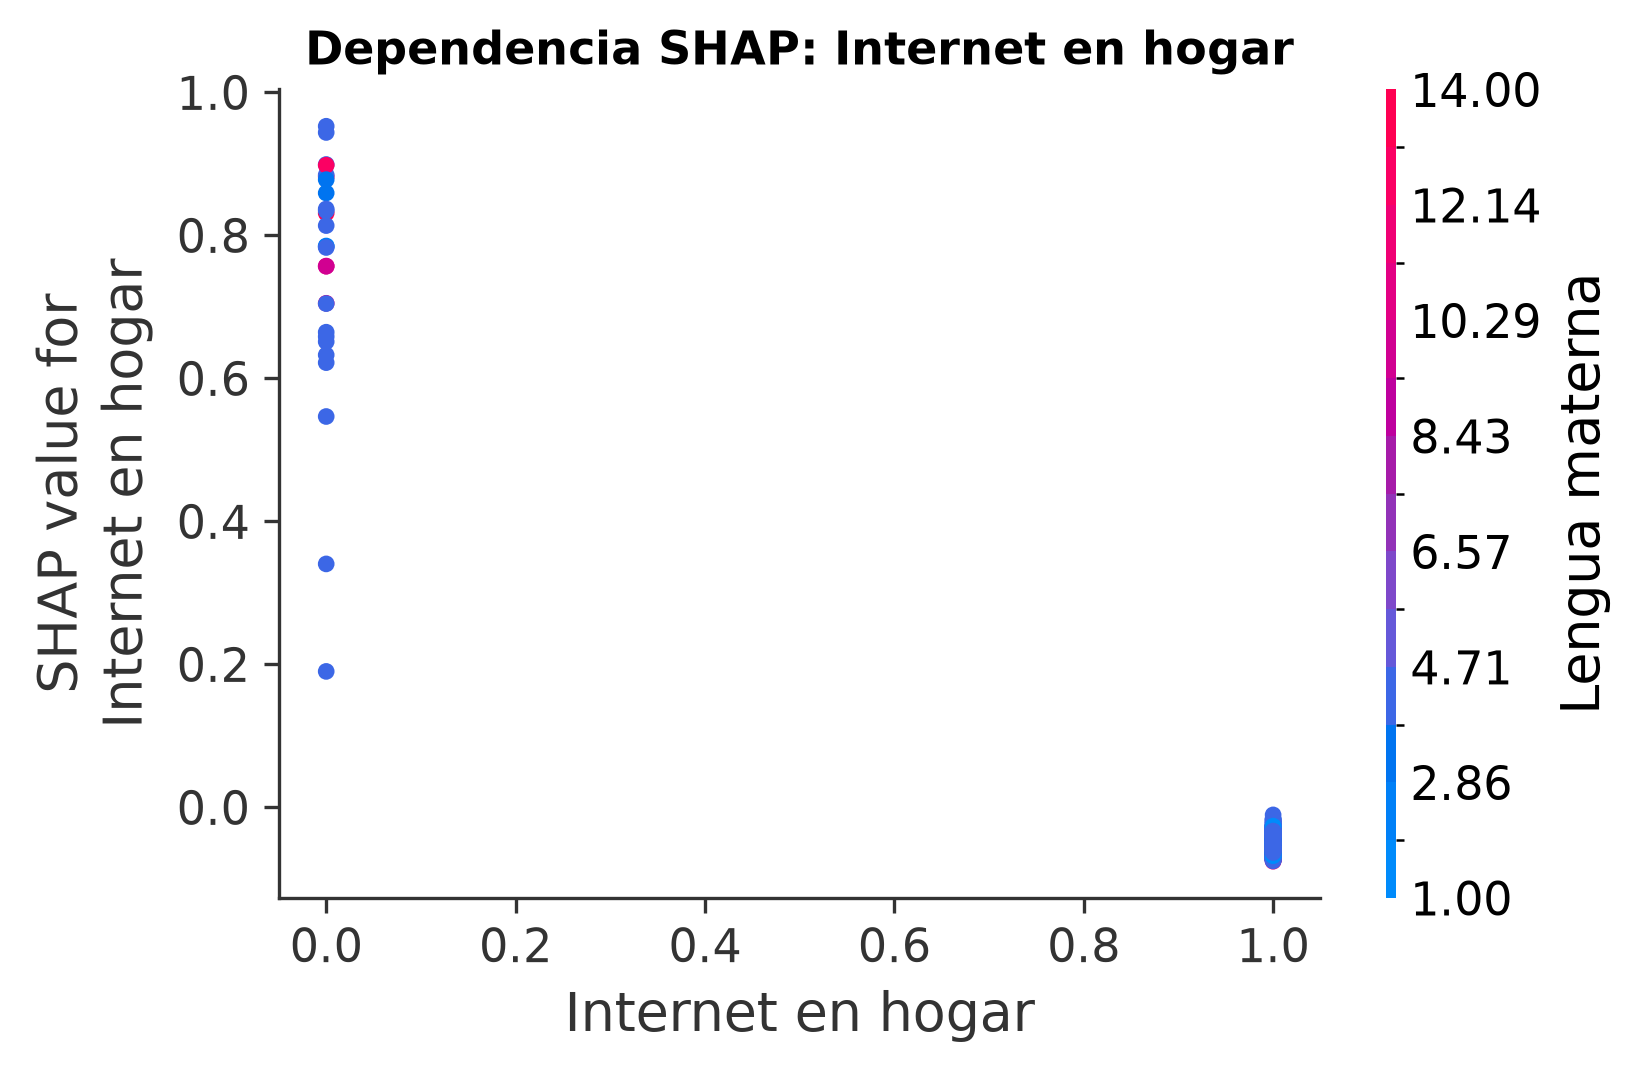

Figura: shap_waterfall_alto.png | SHA-256: caf13f6ebaf303651e8112366f28660778417b892ca723482c6507f3adaaa2ee


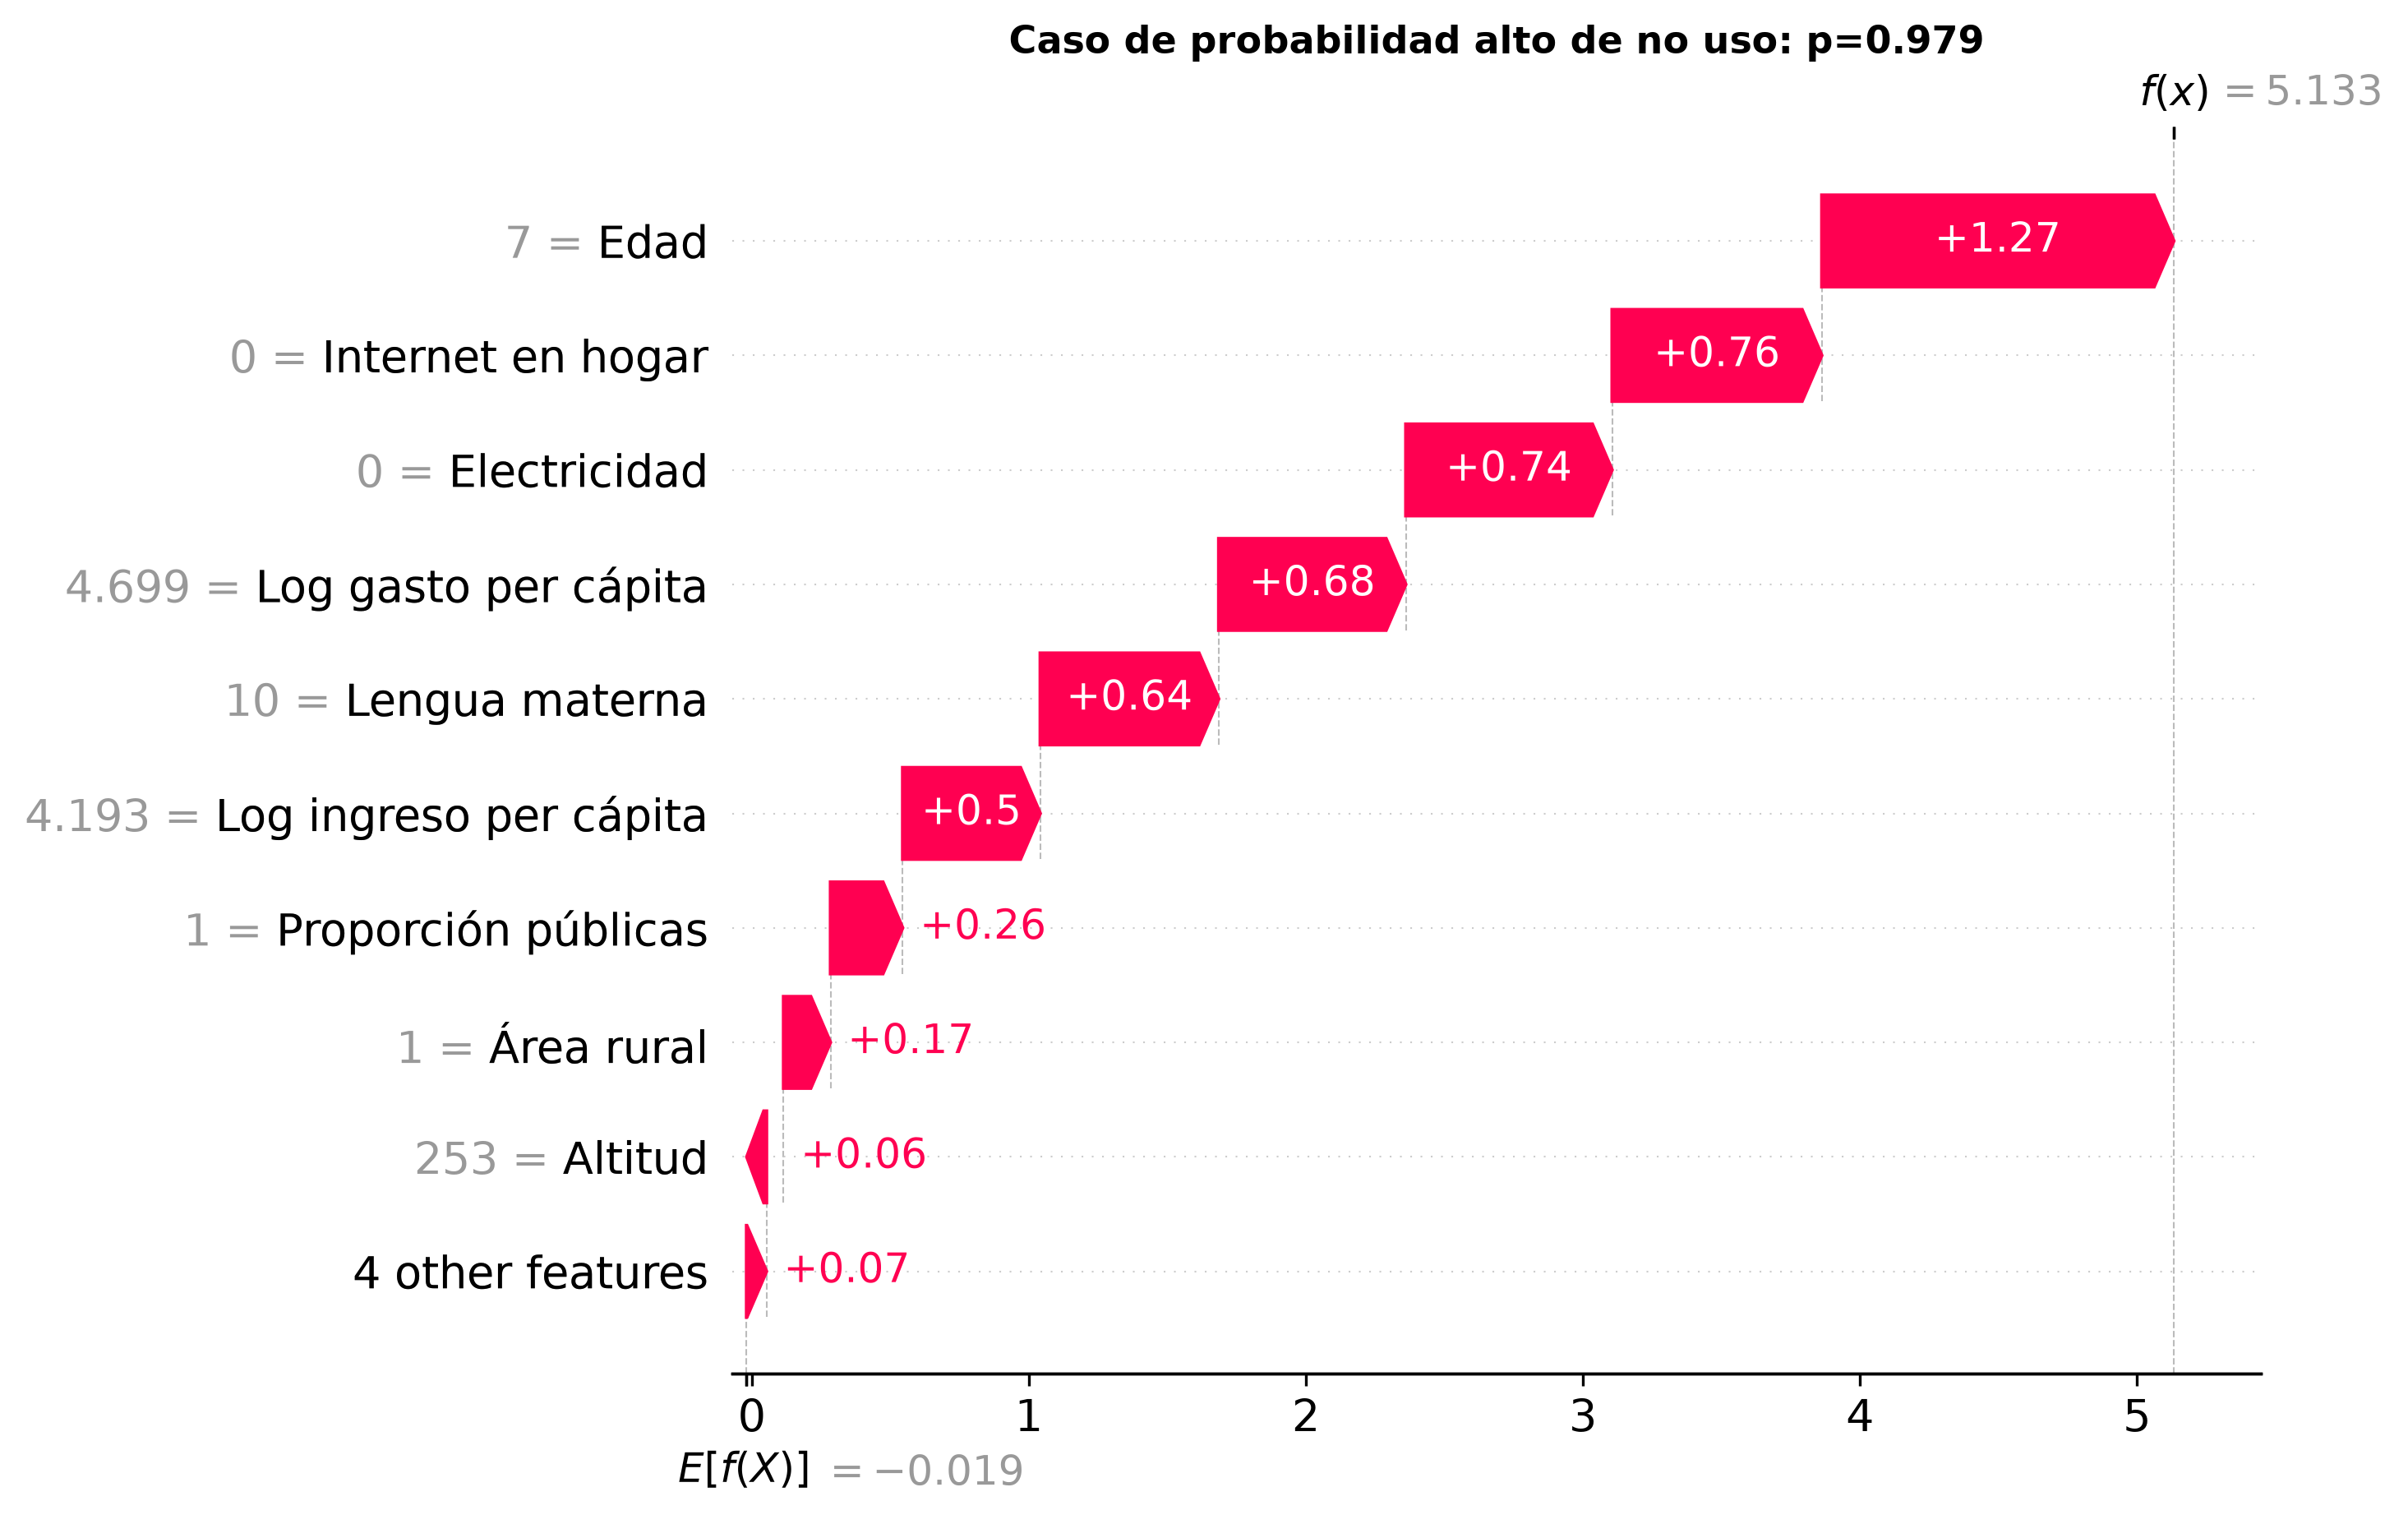

Figura: shap_waterfall_bajo.png | SHA-256: dd5a6ee7754fdfa44489ca3cacc6e18fc0b1c95068712db5a8593837af693094


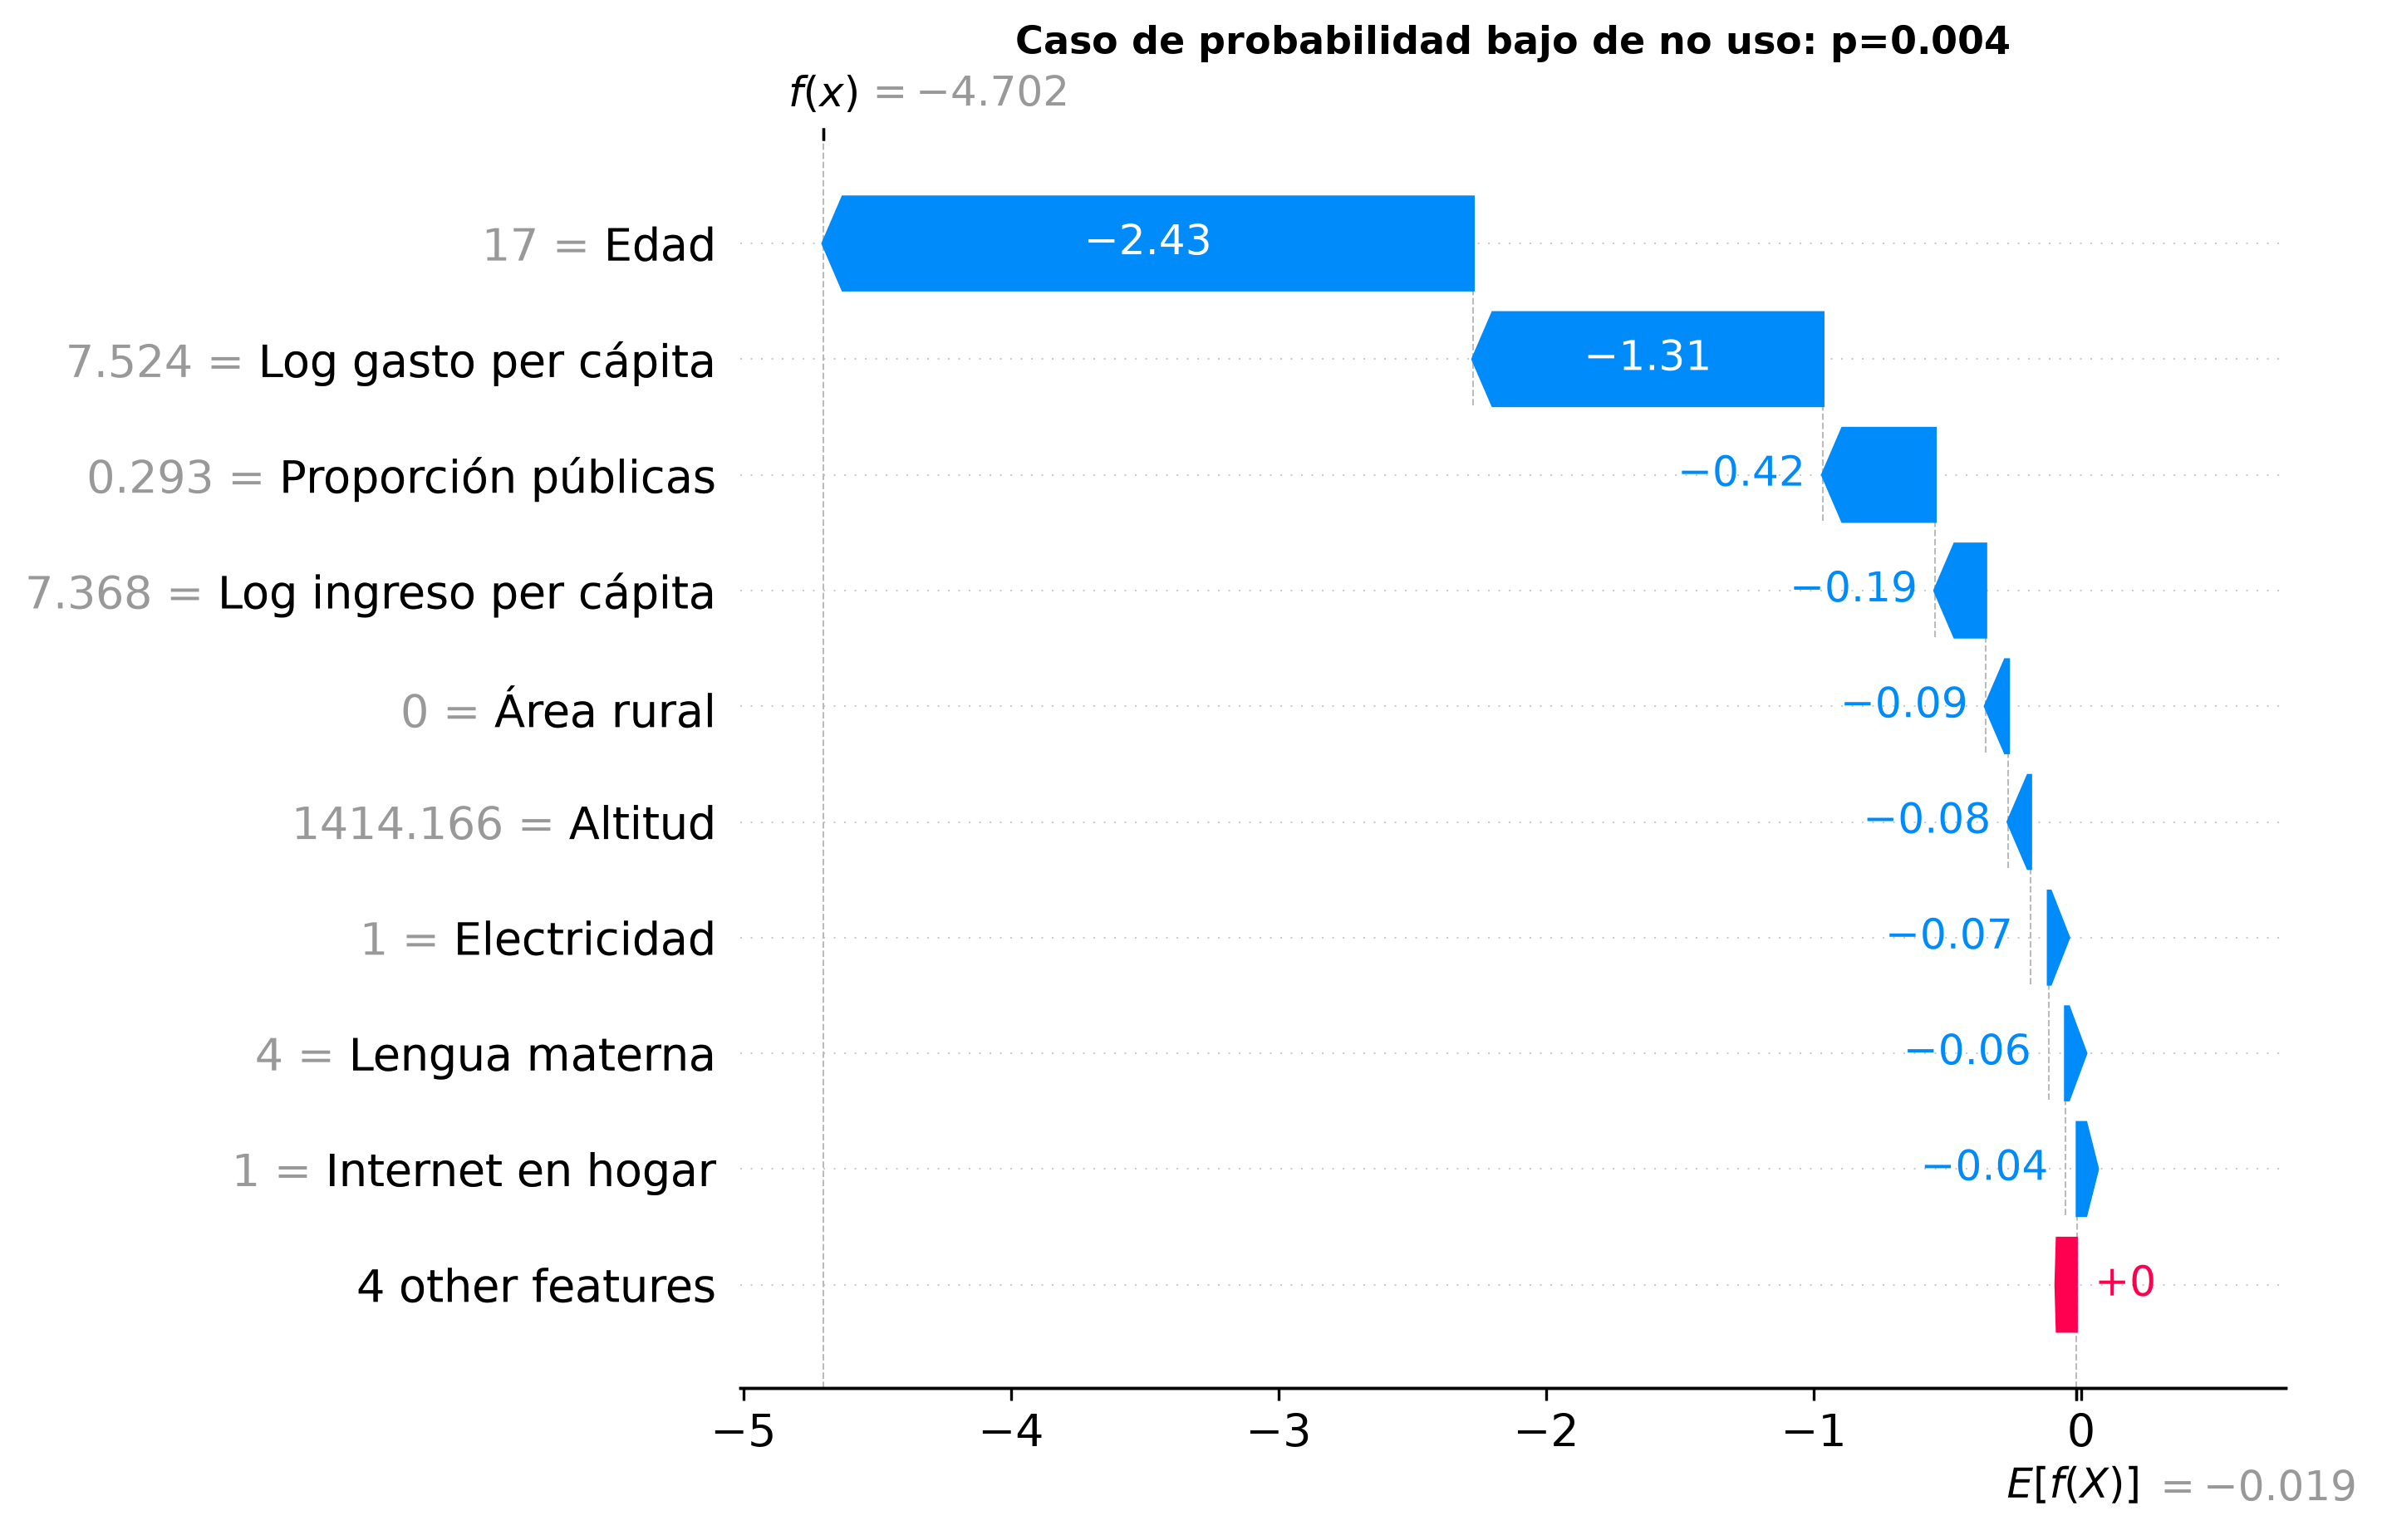

Figura: shap_interaction_1.png | SHA-256: fc3fb575b5a86123bdd8f8c4e683be1c46a4c2ce57fe2f13112c43502c73b171


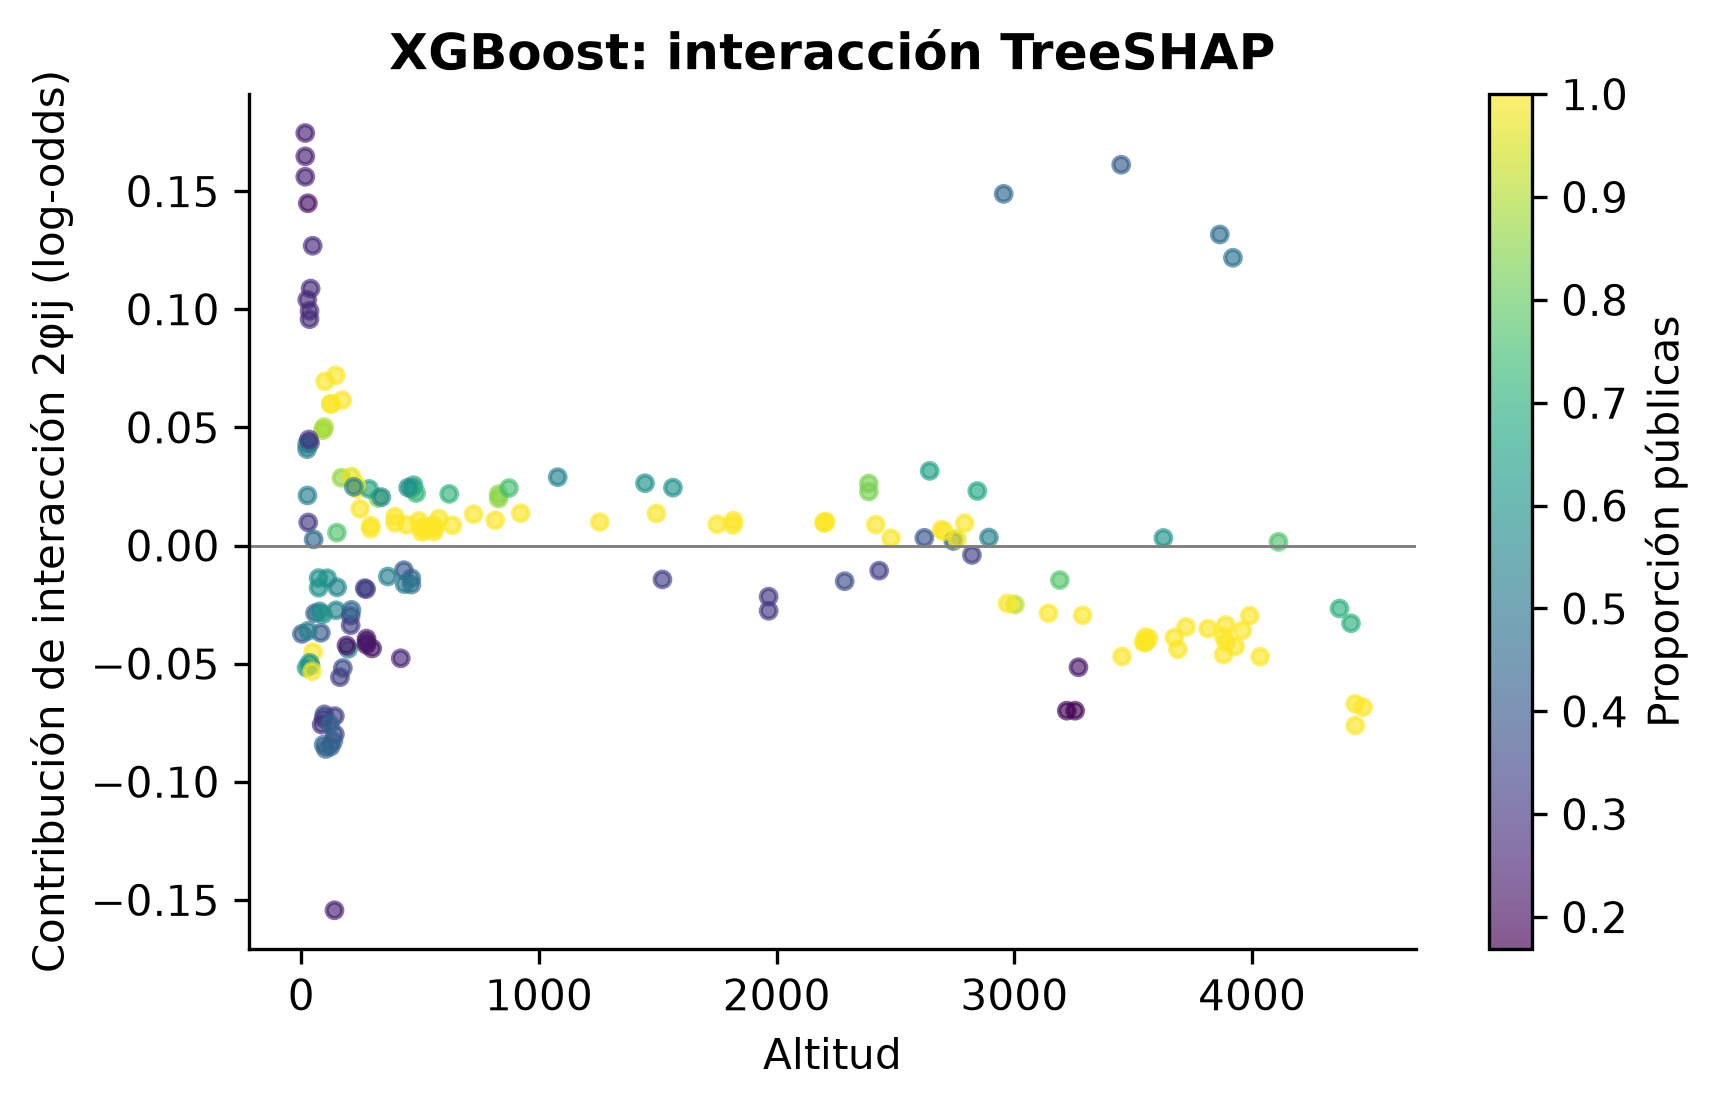

Figura: shap_interaction_2.png | SHA-256: 862c15359e8ba1610cc39c8d137dd2e4f9cddd73d57a1065a8163a436f195b20


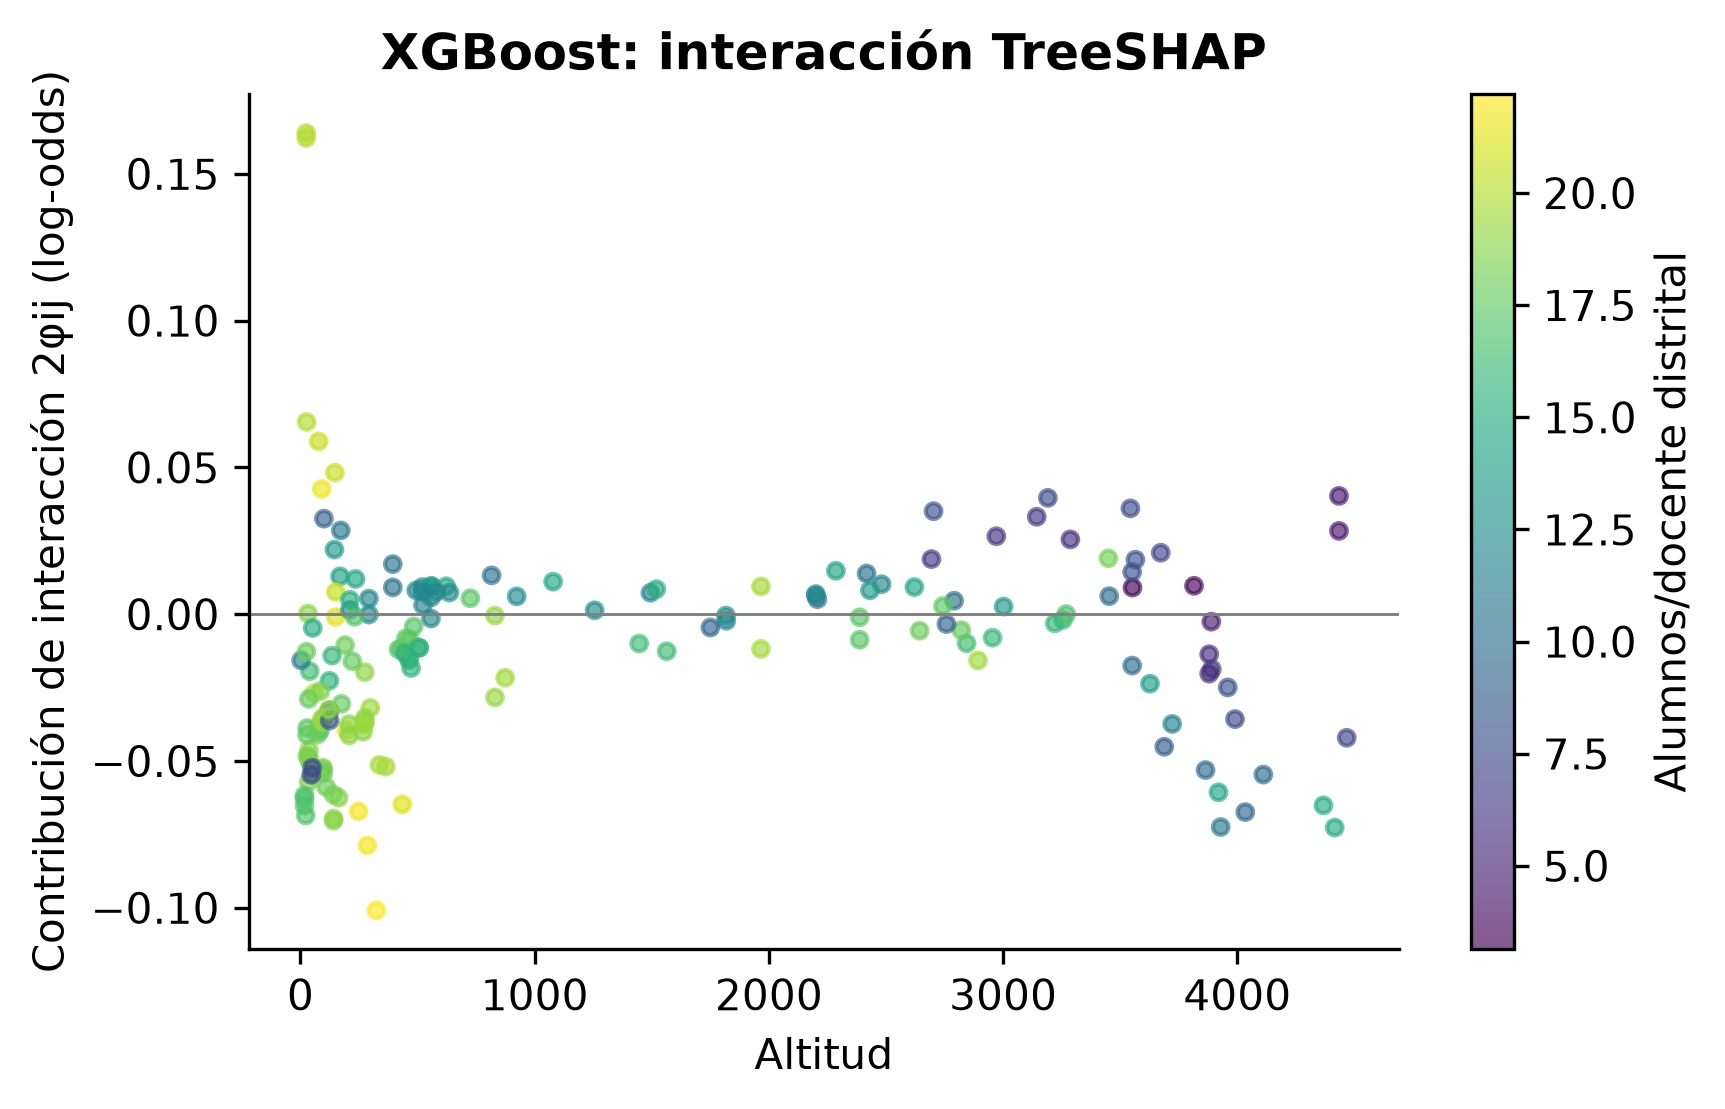

In [5]:
detail=audit('shap')
print('Modelo:',detail['model'],'| Casos:',detail['n_explained'],'| Residuo:',detail['max_additivity_residual'])
display(pd.DataFrame(detail['importance']).sort_values('mean_abs_shap',ascending=False))
print('Complemento:',detail['complementary_model'],'| Residuo:',detail['xgboost_residual'])
table('shap_importance.csv')
table('shap_interactions_xgboost.csv')
figure('shap_beeswarm.png')
figure('shap_dependence_1.png')
figure('shap_dependence_2.png')
figure('shap_waterfall_alto.png')
figure('shap_waterfall_bajo.png')
figure('shap_interaction_1.png')
figure('shap_interaction_2.png')